## Installation

In [173]:

pip install ucimlrepo tensorflow keras scikit-learn pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [174]:
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import numpy as np

import sklearn
print(sklearn.__version__)

import tensorflow as tf
print(tf.__version__)

import keras
print(keras.__version__)

import pandas as pd
print(pd.__version__)

1.9.0
2.21.0
3.15.1
3.0.5


## Data download and exploration

In [175]:

from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
chronic_kidney_disease = fetch_ucirepo(id=336) 
  
# data (as pandas dataframes) 
X = chronic_kidney_disease.data.features 
y = chronic_kidney_disease.data.targets 
  
# metadata 
print("METADATA")
print(chronic_kidney_disease.metadata) 
  
# variable information 
print("VARIABLE INFORMATION")
print(chronic_kidney_disease.variables)

METADATA
{'uci_id': 336, 'name': 'Chronic Kidney Disease', 'repository_url': 'https://archive.ics.uci.edu/dataset/336/chronic+kidney+disease', 'data_url': 'https://archive.ics.uci.edu/static/public/336/data.csv', 'abstract': 'This dataset can be used to predict the chronic kidney disease and it can be collected from the hospital nearly 2 months of period.', 'area': 'Other', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 400, 'num_features': 24, 'feature_types': ['Real'], 'demographics': ['Age'], 'target_col': ['class'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 2015, 'last_updated': 'Mon Mar 04 2024', 'dataset_doi': '10.24432/C5G020', 'creators': ['L. Rubini', 'P. Soundarapandian', 'P. Eswaran'], 'intro_paper': None, 'additional_info': {'summary': 'We use the following representation to collect the dataset\r\n                        age\t\t-\tage\t\r\n\t\t\tbp\t\t-\tblood pressure\r\n\

In [176]:
%pip install pandas
import pandas as pd

Note: you may need to restart the kernel to use updated packages.


In [177]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.width", None)

In [178]:
df = pd.DataFrame(X)
df2 = pd.DataFrame(y)
print("INFO")
print(df.info())
print("DESCRIPTION")
print(df.describe())
print("ISNULL")
print(df.isnull().sum())
print("DUPES")
print(df.duplicated().sum())
print("DF")
print(df)
print("INFO")
print(df2.info())
print("DESCRIPTION")
print(df2.describe())
print("ISNULL")
print(df2.isnull().sum())
print("DUPES")
print(df2.duplicated().sum())
print("DF2")
print(df2)

INFO
<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 24 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     391 non-null    float64
 1   bp      388 non-null    float64
 2   sg      353 non-null    float64
 3   al      354 non-null    float64
 4   su      351 non-null    float64
 5   rbc     248 non-null    str    
 6   pc      335 non-null    str    
 7   pcc     396 non-null    str    
 8   ba      396 non-null    str    
 9   bgr     356 non-null    float64
 10  bu      381 non-null    float64
 11  sc      383 non-null    float64
 12  sod     313 non-null    float64
 13  pot     312 non-null    float64
 14  hemo    348 non-null    float64
 15  pcv     329 non-null    float64
 16  wbcc    294 non-null    float64
 17  rbcc    269 non-null    float64
 18  htn     398 non-null    str    
 19  dm      398 non-null    str    
 20  cad     398 non-null    str    
 21  appet   399 non-null    str    
 22  pe      

## Numeric data: outliers, cross-correlation matrix, linear regression.

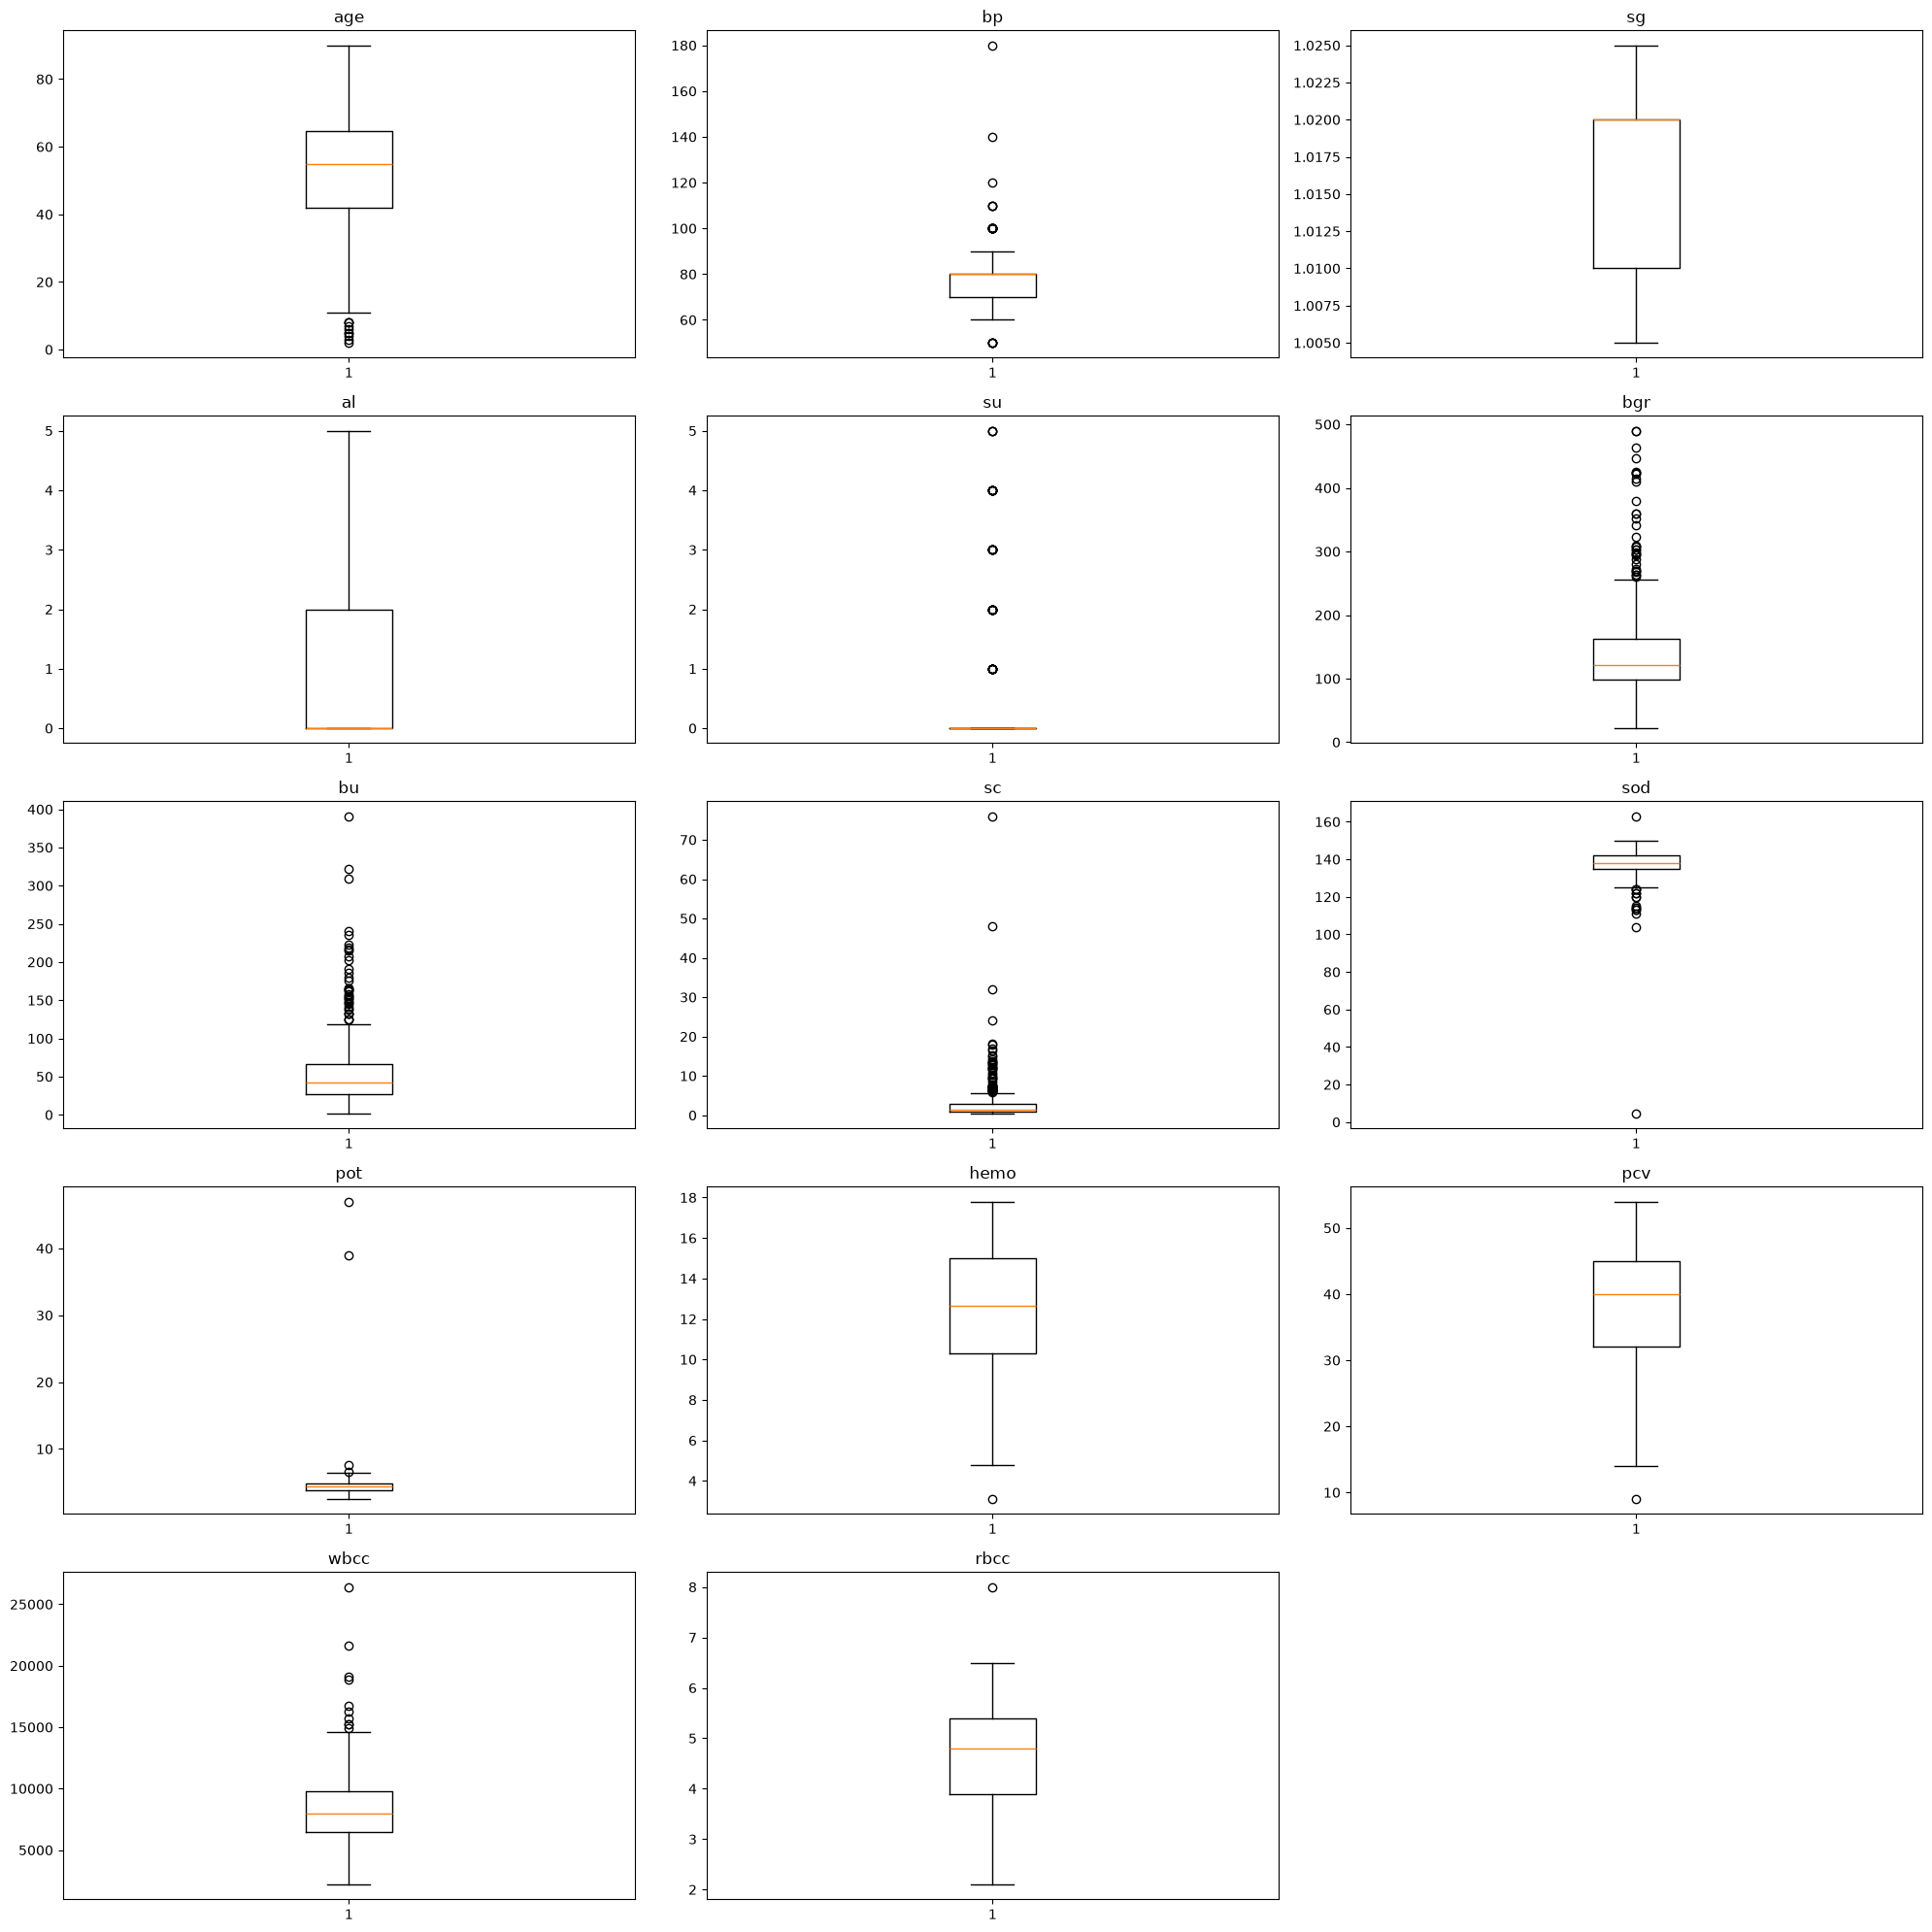

,count,pct,lower_bound,upper_bound
su,61.0,17.38,0.000,0.000
sc,51.0,13.32,-1.950,5.650
bu,38.0,9.97,-31.500,124.500
bp,36.0,9.28,55.000,95.000
bgr,34.0,9.55,3.000,259.000
sod,16.0,5.11,124.500,152.500
age,10.0,2.56,8.250,98.250
wbcc,10.0,3.40,1550.000,14750.000
pot,4.0,1.28,2.150,6.550
hemo,1.0,0.29,3.250,22.050


In [179]:
import numpy as np
import matplotlib.pyplot as plt

numeric_cols = df.select_dtypes(include=[np.number]).columns

# boxplot per numeric column to visually spot outliers
n_cols = 3
n_rows = -(-len(numeric_cols) // n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 4 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):
    ax.boxplot(df[col].dropna())
    ax.set_title(col)

for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# IQR method: flag values outside [Q1 - 1.5*IQR, Q3 + 1.5*IQR] as outliers
def iqr_outlier_bounds(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1  # interquartile range is the difference between the 75th and 25th percentiles
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

outlier_summary = {}
for col in numeric_cols:
    lower, upper = iqr_outlier_bounds(df[col])
    mask = (df[col] < lower) | (df[col] > upper)  # True where value is an outlier
    outlier_summary[col] = {
        "count": int(mask.sum()),  # number of outlier rows for this column
        "pct": round(100 * mask.sum() / df[col].notna().sum(), 2),  # outliers as % of non-null rows
        "lower_bound": round(lower, 3),  # anything below this is a low outlier
        "upper_bound": round(upper, 3),  # anything above this is a high outlier
    }

# summary table, one row per column, worst offenders (most outliers) first
outlier_df = pd.DataFrame(outlier_summary).T.sort_values("count", ascending=False)
outlier_df

# Box — spans Q1 (25th percentile) to Q3 (75th percentile), i.e. the middle 50% of values (the IQR). The line inside the box is the median (Q2).
# Whiskers — extend to the most extreme data points still within Q1 - 1.5×IQR and Q3 + 1.5×IQR.
# Circles beyond the whiskers — individual points flagged as outliers (outside that 1.5×IQR range) — this is exactly what the outlier_summary/outlier_df table right below it counts numerically per column.


In [180]:
df_duplicates = df[df.duplicated(keep=False)]
df2_duplicates = df2[df2.duplicated(keep=False)]

print(f"df duplicate rows: {len(df_duplicates)}")
print(f"df2 duplicate rows: {len(df2_duplicates)}")

df duplicate rows: 0
df2 duplicate rows: 400


In [181]:
print(df2.to_string())

      class
0       ckd
1       ckd
2       ckd
3       ckd
4       ckd
5       ckd
6       ckd
7       ckd
8       ckd
9       ckd
10      ckd
11      ckd
12      ckd
13      ckd
14      ckd
15      ckd
16      ckd
17      ckd
18      ckd
19      ckd
20      ckd
21      ckd
22      ckd
23      ckd
24      ckd
25      ckd
26      ckd
27      ckd
28      ckd
29      ckd
30      ckd
31      ckd
32      ckd
33      ckd
34      ckd
35      ckd
36      ckd
37    ckd\t
38      ckd
39      ckd
40      ckd
41      ckd
42      ckd
43      ckd
44      ckd
45      ckd
46      ckd
47      ckd
48      ckd
49      ckd
50      ckd
51      ckd
52      ckd
53      ckd
54      ckd
55      ckd
56      ckd
57      ckd
58      ckd
59      ckd
60      ckd
61      ckd
62      ckd
63      ckd
64      ckd
65      ckd
66      ckd
67      ckd
68      ckd
69      ckd
70      ckd
71      ckd
72      ckd
73      ckd
74      ckd
75      ckd
76      ckd
77      ckd
78      ckd
79      ckd
80      ckd
81      ckd
82  

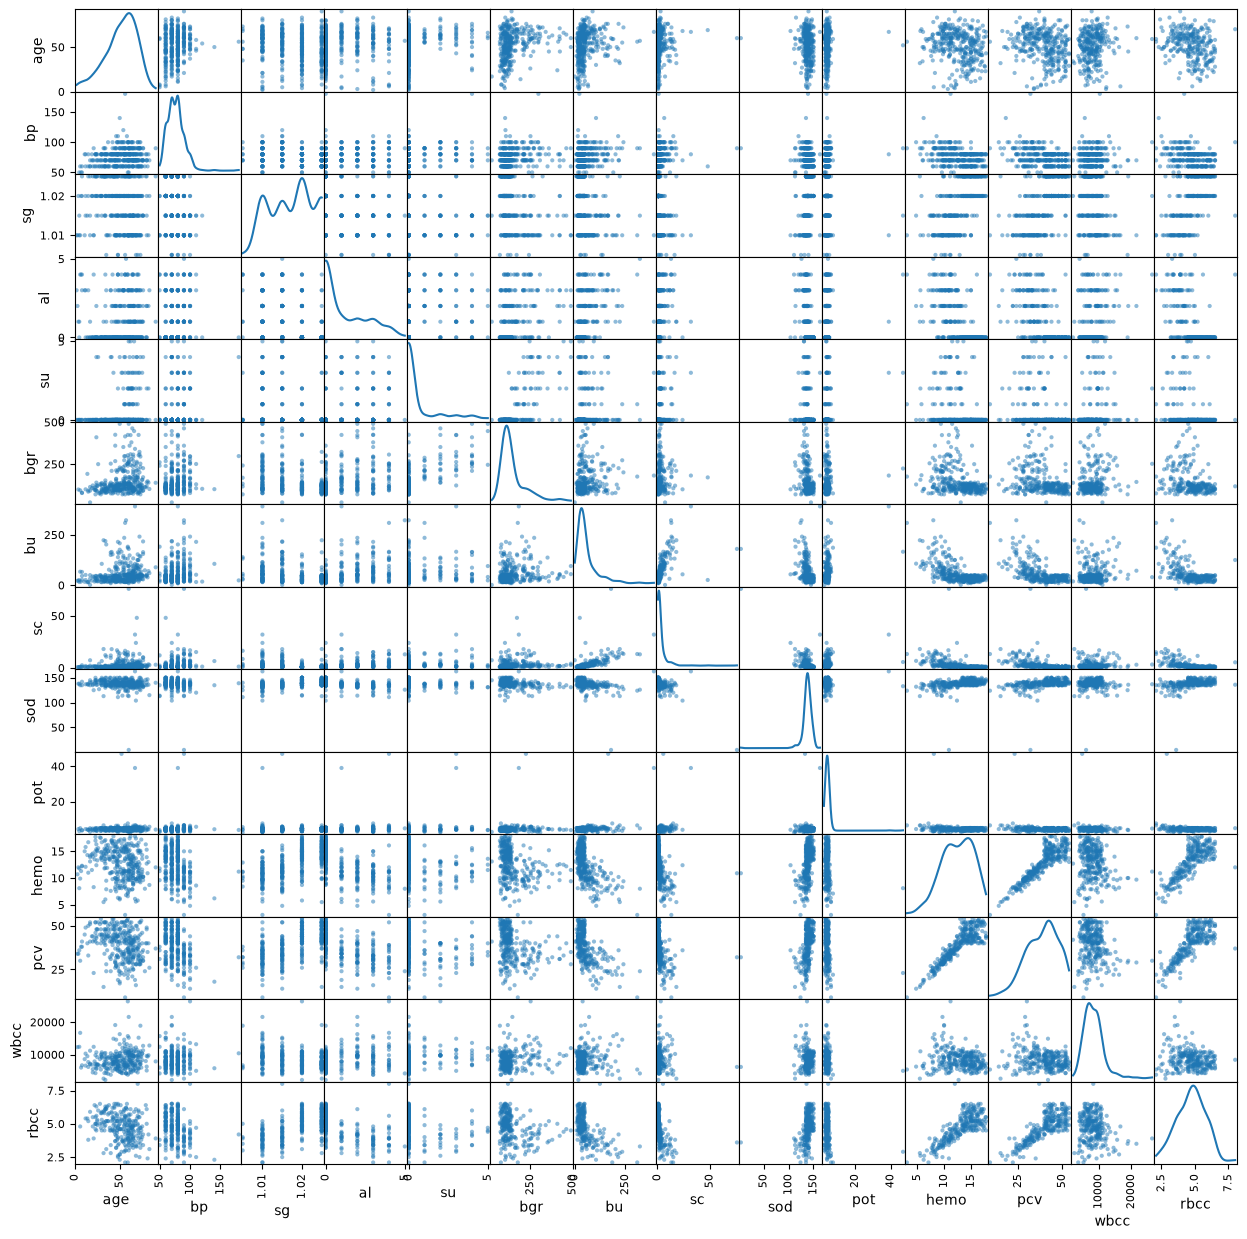

In [182]:
scatter_matrix = pd.plotting.scatter_matrix(df[numeric_cols], figsize=(15, 15), diagonal='kde', alpha=0.5)

In [183]:
df[numeric_cols].corr()

,age,bp,sg,al,su,bgr,bu,sc,sod,pot,hemo,pcv,wbcc,rbcc
age,1.000000,0.159480,-0.191096,0.122091,0.220866,0.244992,0.196985,0.132531,-0.100046,0.058377,-0.192928,-0.242119,0.118339,-0.268896
bp,0.159480,1.000000,-0.218836,0.160689,0.222576,0.160193,0.188517,0.146222,-0.116422,0.075151,-0.306540,-0.326319,0.029753,-0.261936
sg,-0.191096,-0.218836,1.000000,-0.469760,-0.296234,-0.374710,-0.314295,-0.361473,0.412190,-0.072787,0.602582,0.603560,-0.236215,0.579476
al,0.122091,0.160689,-0.469760,1.000000,0.269305,0.379464,0.453528,0.399198,-0.459896,0.129038,-0.634632,-0.611891,0.231989,-0.566437
su,0.220866,0.222576,-0.296234,0.269305,1.000000,0.717827,0.168583,0.223244,-0.131776,0.219450,-0.224775,-0.239189,0.184893,-0.237448
bgr,0.244992,0.160193,-0.374710,0.379464,0.717827,1.000000,0.143322,0.114875,-0.267848,0.066966,-0.306189,-0.301385,0.150015,-0.281541
bu,0.196985,0.188517,-0.314295,0.453528,0.168583,0.143322,1.000000,0.586368,-0.323054,0.357049,-0.610360,-0.607621,0.050462,-0.579087
sc,0.132531,0.146222,-0.361473,0.399198,0.223244,0.114875,0.586368,1.000000,-0.690158,0.326107,-0.401670,-0.404193,-0.006390,-0.400852
sod,-0.100046,-0.116422,0.412190,-0.459896,-0.131776,-0.267848,-0.323054,-0.690158,1.000000,0.097887,0.365183,0.376914,0.007277,0.344873
pot,0.058377,0.075151,-0.072787,0.129038,0.219450,0.066966,0.357049,0.326107,0.097887,1.000000,-0.133746,-0.163182,-0.105576,-0.158309


In [184]:
corr_matrix = df[numeric_cols].corr()
upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
strong_corr = upper_triangle.stack()
strong_corr = strong_corr[(strong_corr >= 0.5) & (strong_corr < 1.0)].sort_values(ascending=False)
strong_corr

hemo  pcv     0.895382
      rbcc    0.798880
pcv   rbcc    0.791625
su    bgr     0.717827
sg    pcv     0.603560
      hemo    0.602582
bu    sc      0.586368
sg    rbcc    0.579476
dtype: float64

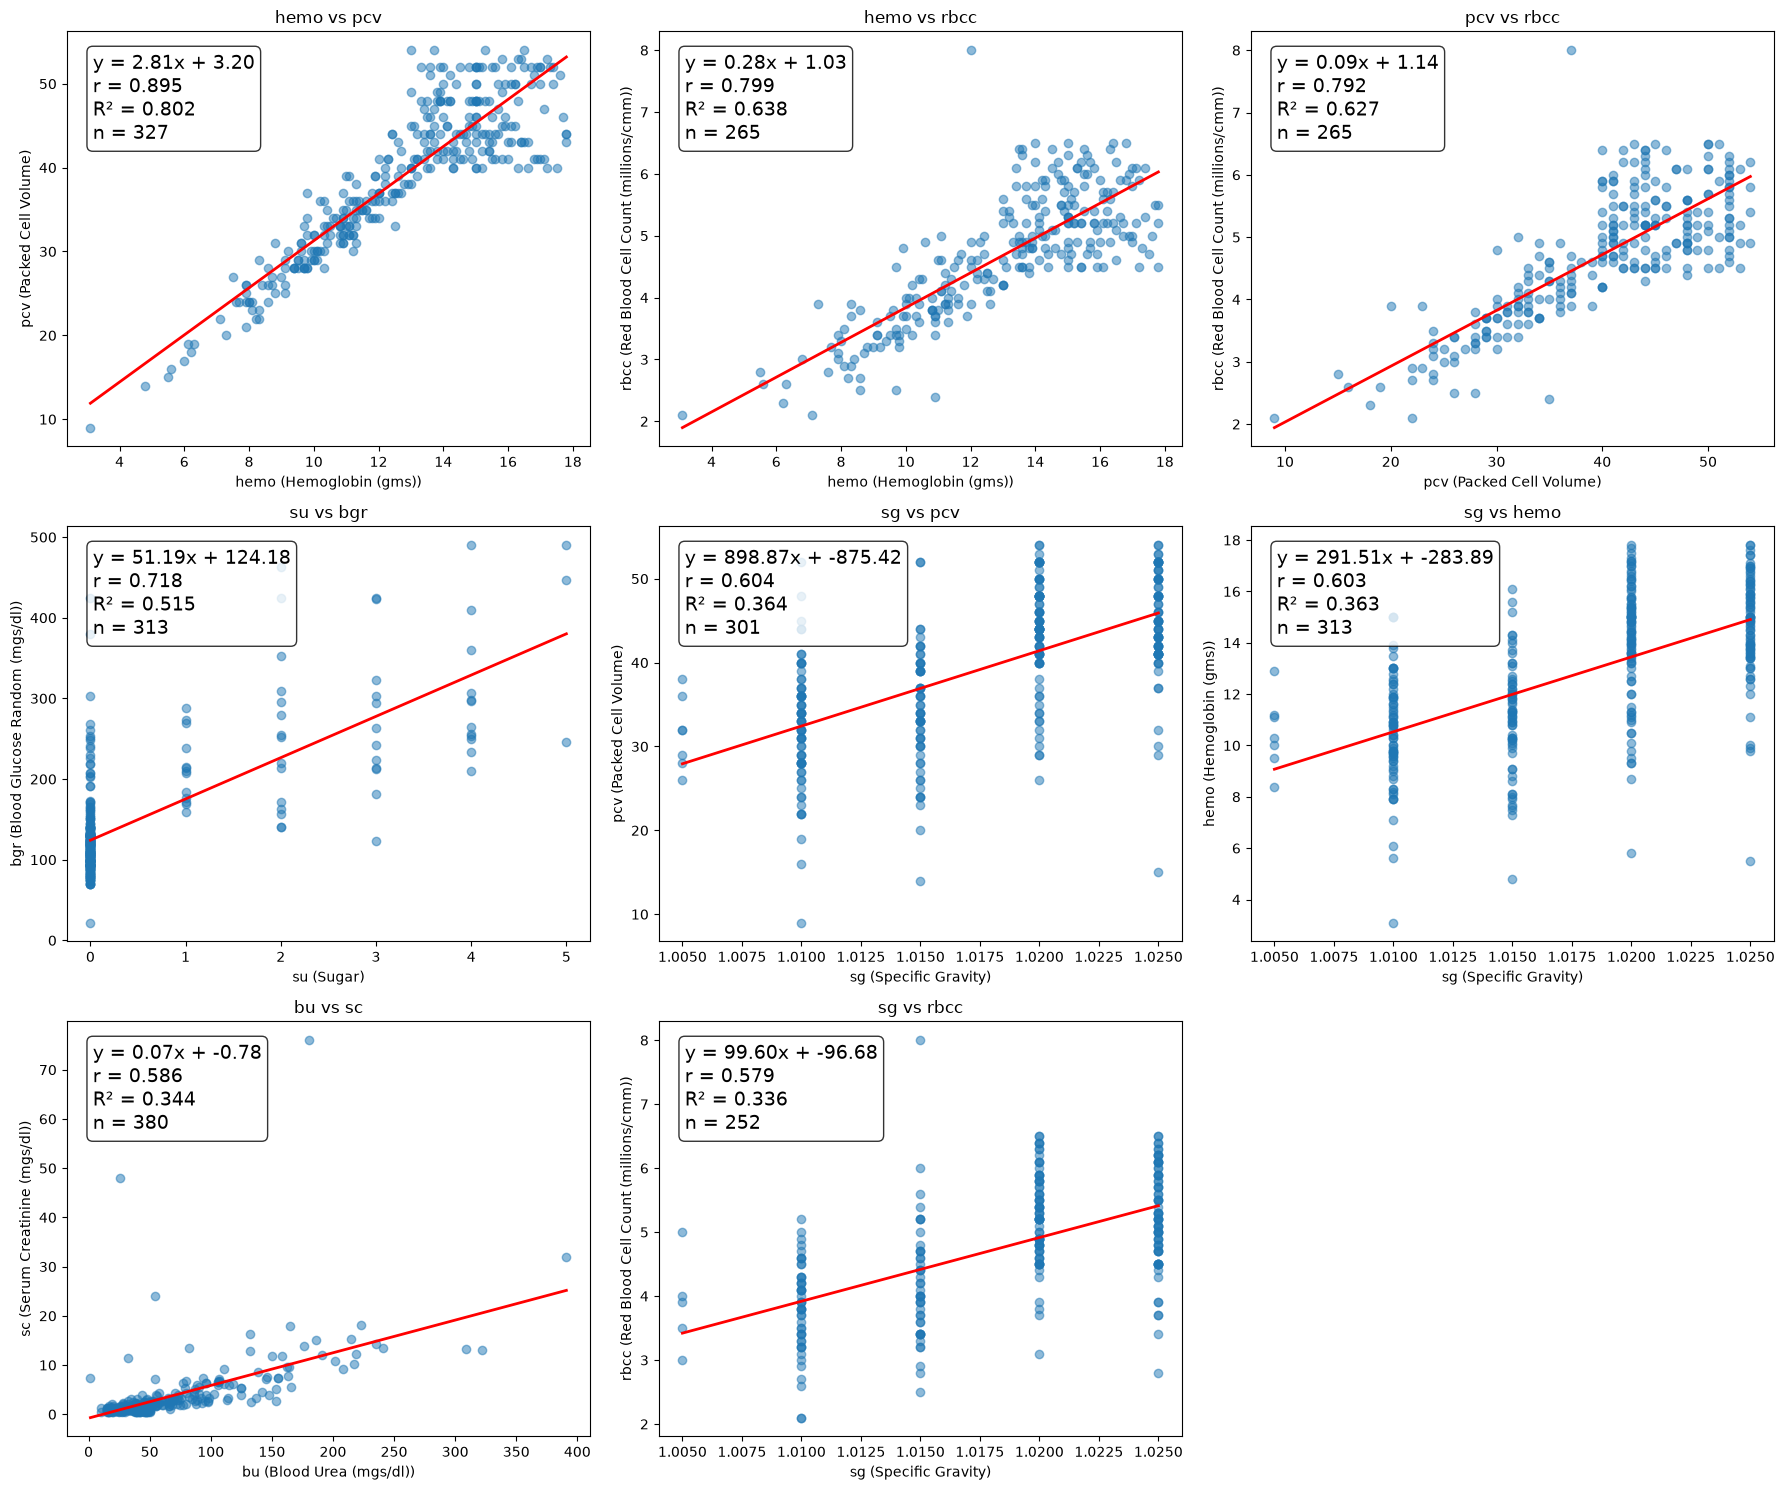

In [185]:
column_descriptions = {
    "age": "Age (years)",
    "bp": "Blood Pressure (mm/Hg)",
    "sg": "Specific Gravity",
    "al": "Albumin",
    "su": "Sugar",
    "bgr": "Blood Glucose Random (mgs/dl)",
    "bu": "Blood Urea (mgs/dl)",
    "sc": "Serum Creatinine (mgs/dl)",
    "sod": "Sodium (mEq/L)",
    "pot": "Potassium (mEq/L)",
    "hemo": "Hemoglobin (gms)",
    "pcv": "Packed Cell Volume",
    "wbcc": "White Blood Cell Count (cells/cmm)",
    "rbcc": "Red Blood Cell Count (millions/cmm)",
}

pairs = strong_corr.index.tolist()

n_cols = 3
n_rows = -(-len(pairs) // n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))
axes = axes.flatten()

for i, (col_x, col_y) in enumerate(pairs):
    pair_data = df[[col_x, col_y]].dropna()
    x = pair_data[col_x]
    y = pair_data[col_y]

    axes[i].scatter(x, y, alpha=0.5)

    slope, intercept = np.polyfit(x, y, 1)
    x_line = np.linspace(x.min(), x.max(), 100)
    axes[i].plot(x_line, slope * x_line + intercept, color="red", linewidth=2)

    r = strong_corr[(col_x, col_y)]
    stats_text = (
        f"y = {slope:.2f}x + {intercept:.2f}\n"
        f"r = {r:.3f}\n"
        f"R² = {r ** 2:.3f}\n"
        f"n = {len(pair_data)}"
    )
    axes[i].text(
        0.05, 0.95, stats_text,
        transform=axes[i].transAxes,
        verticalalignment="top",
        fontsize=14,
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.8),
    )

    axes[i].set_xlabel(f"{col_x} ({column_descriptions.get(col_x, col_x)})")
    axes[i].set_ylabel(f"{col_y} ({column_descriptions.get(col_y, col_y)})")
    axes[i].set_title(f"{col_x} vs {col_y}")

for j in range(len(pairs), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## Numeric data split by class: cross-correlation matrix, linear regression.

In [186]:
df_numeric = df[numeric_cols].copy()
df_first_half = df_numeric.iloc[0:250]
df_second_half = df_numeric.iloc[250:400]

print(df_first_half.shape)
print(df_second_half.shape)

(250, 14)
(150, 14)


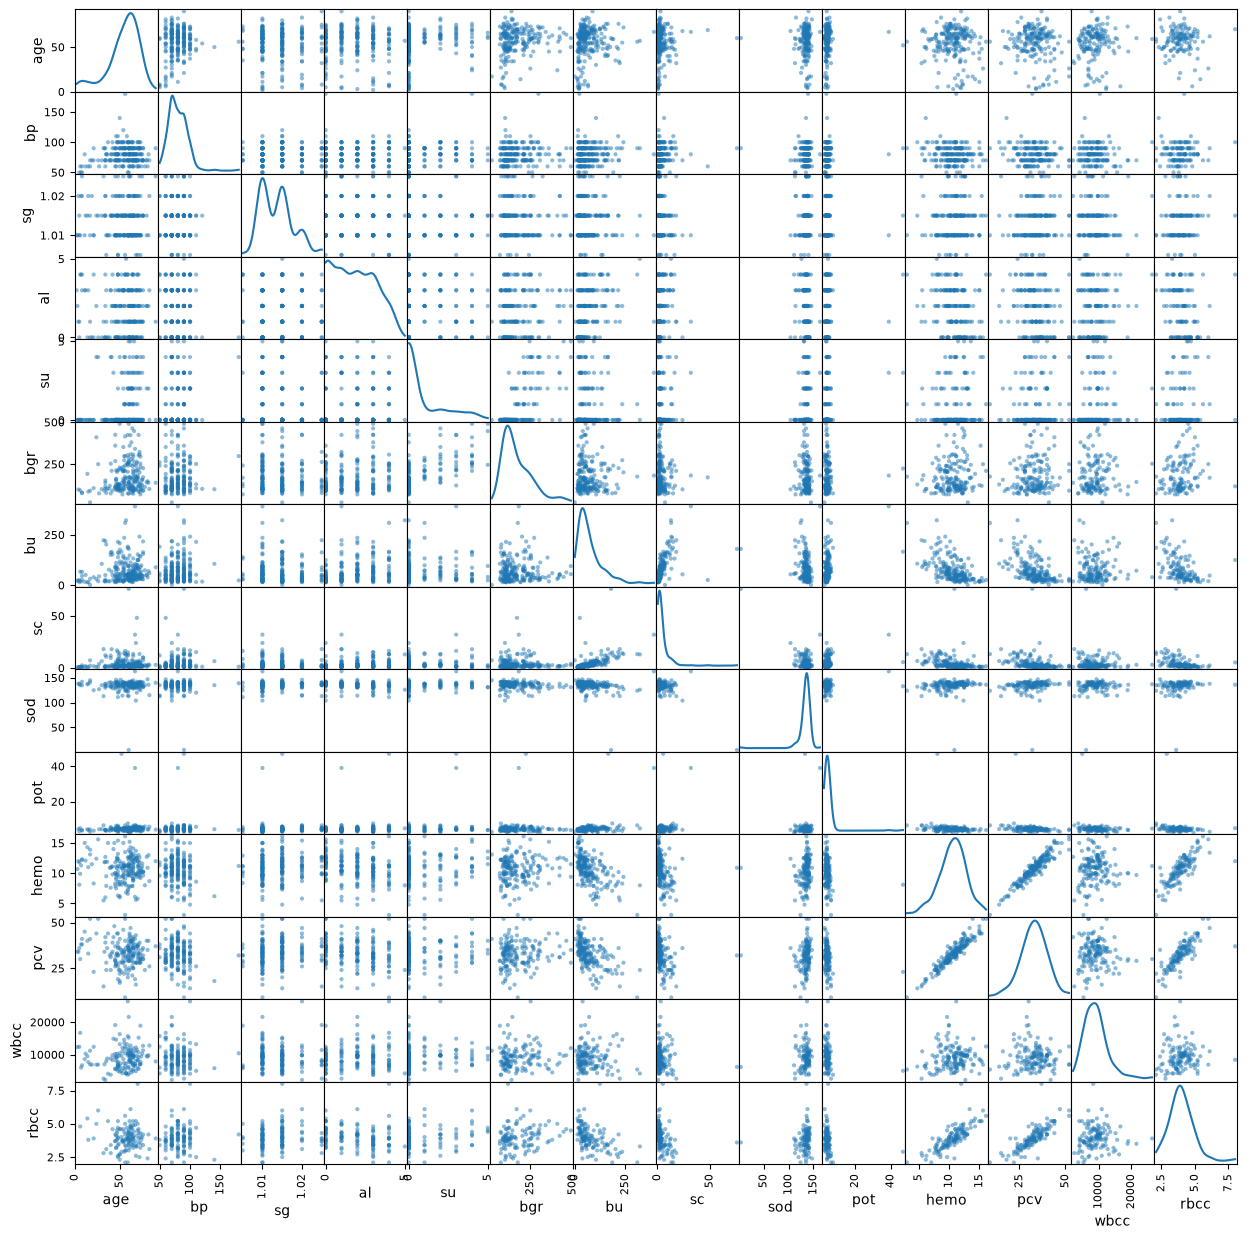

In [187]:
scatter_matrix_first_half = pd.plotting.scatter_matrix(df_first_half[numeric_cols], figsize=(15, 15), diagonal='kde', alpha=0.5)

In [188]:
df_first_half[numeric_cols].corr()

,age,bp,sg,al,su,bgr,bu,sc,sod,pot,hemo,pcv,wbcc,rbcc
age,1.000000,0.139914,-0.051072,-0.019526,0.202558,0.157971,0.128488,0.077511,-0.024347,0.057800,-0.079249,-0.133378,0.054535,-0.060833
bp,0.139914,1.000000,0.006266,-0.036475,0.144743,0.044731,0.103476,0.068781,0.023079,0.059091,-0.152088,-0.166668,-0.043500,0.047398
sg,-0.051072,0.006266,1.000000,-0.016263,-0.081830,-0.078618,-0.075402,-0.132552,0.128031,-0.012715,0.079148,0.098974,-0.080357,0.105246
al,-0.019526,-0.036475,-0.016263,1.000000,0.074083,0.135627,0.313240,0.214068,-0.218883,0.094635,-0.299217,-0.272048,0.100120,-0.217640
su,0.202558,0.144743,-0.081830,0.074083,1.000000,0.676076,0.047734,0.099910,0.098796,0.202382,0.105882,0.070367,0.111833,0.091983
bgr,0.157971,0.044731,-0.078618,0.135627,0.676076,1.000000,-0.032205,-0.052915,-0.084598,0.029099,0.104109,0.101338,0.040322,0.193075
bu,0.128488,0.103476,-0.075402,0.313240,0.047734,-0.032205,1.000000,0.542641,-0.189845,0.367642,-0.567667,-0.559678,-0.066990,-0.463866
sc,0.077511,0.068781,-0.132552,0.214068,0.099910,-0.052915,0.542641,1.000000,-0.677810,0.330187,-0.276875,-0.282372,-0.100328,-0.275075
sod,-0.024347,0.023079,0.128031,-0.218883,0.098796,-0.084598,-0.189845,-0.677810,1.000000,0.185020,0.125149,0.146802,0.103582,0.121540
pot,0.057800,0.059091,-0.012715,0.094635,0.202382,0.029099,0.367642,0.330187,0.185020,1.000000,-0.159390,-0.192354,-0.162138,-0.171079


In [189]:
corr_matrix = df_first_half[numeric_cols].corr()
upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)) #This line creates a mask for the upper triangle of the correlation matrix, setting the lower triangle and diagonal to NaN. This is done to avoid duplicate pairs and self-correlations when analyzing the correlations between different numeric columns in the first half of the dataset.
strong_corr_first_half = upper_triangle.stack() #This line stacks the upper triangle of the correlation matrix into a Series, where each index is a tuple of column names and the value is the correlation coefficient. This allows for easier filtering and sorting of strong correlations in the first half of the dataset.
#print(strong_corr_first_half)
strong_corr_first_half = strong_corr_first_half[(strong_corr_first_half >= 0.5) & (strong_corr_first_half <= 1)].sort_values(ascending=False)
strong_corr_first_half

hemo  pcv     0.948590
pcv   rbcc    0.795086
hemo  rbcc    0.781629
su    bgr     0.676076
bu    sc      0.542641
dtype: float64

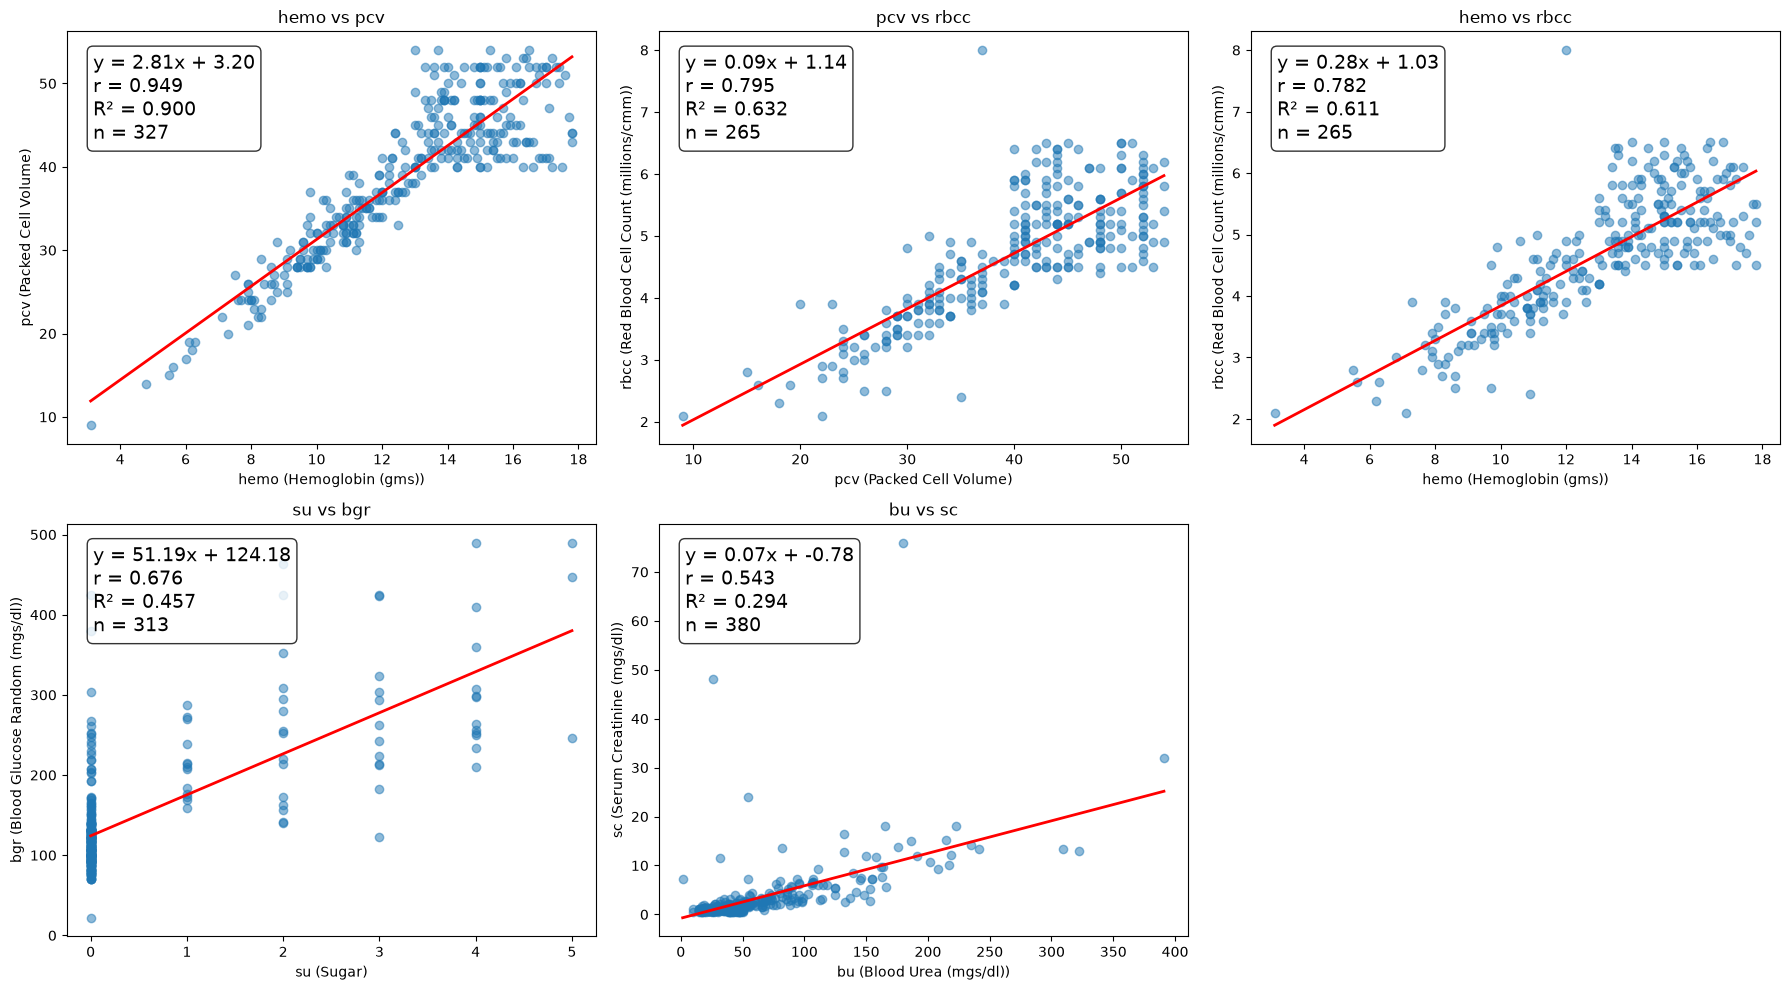

In [190]:
column_descriptions = {
    "age": "Age (years)",
    "bp": "Blood Pressure (mm/Hg)",
    "sg": "Specific Gravity",
    "al": "Albumin",
    "su": "Sugar",
    "bgr": "Blood Glucose Random (mgs/dl)",
    "bu": "Blood Urea (mgs/dl)",
    "sc": "Serum Creatinine (mgs/dl)",
    "sod": "Sodium (mEq/L)",
    "pot": "Potassium (mEq/L)",
    "hemo": "Hemoglobin (gms)",
    "pcv": "Packed Cell Volume",
    "wbcc": "White Blood Cell Count (cells/cmm)",
    "rbcc": "Red Blood Cell Count (millions/cmm)",
}

pairs = strong_corr_first_half.index.tolist()

n_cols = 3
n_rows = -(-len(pairs) // n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))
axes = axes.flatten()

for i, (col_x, col_y) in enumerate(pairs):
    pair_data = df[[col_x, col_y]].dropna()
    x = pair_data[col_x]
    y = pair_data[col_y]

    axes[i].scatter(x, y, alpha=0.5)

    slope, intercept = np.polyfit(x, y, 1)
    x_line = np.linspace(x.min(), x.max(), 100)
    axes[i].plot(x_line, slope * x_line + intercept, color="red", linewidth=2)

    r = strong_corr_first_half[(col_x, col_y)]
    stats_text = (
        f"y = {slope:.2f}x + {intercept:.2f}\n"
        f"r = {r:.3f}\n"
        f"R² = {r ** 2:.3f}\n"
        f"n = {len(pair_data)}"
    )
    axes[i].text(
        0.05, 0.95, stats_text,
        transform=axes[i].transAxes,
        verticalalignment="top",
        fontsize=14,
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.8),
    )

    axes[i].set_xlabel(f"{col_x} ({column_descriptions.get(col_x, col_x)})")
    axes[i].set_ylabel(f"{col_y} ({column_descriptions.get(col_y, col_y)})")
    axes[i].set_title(f"{col_x} vs {col_y}")

for j in range(len(pairs), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

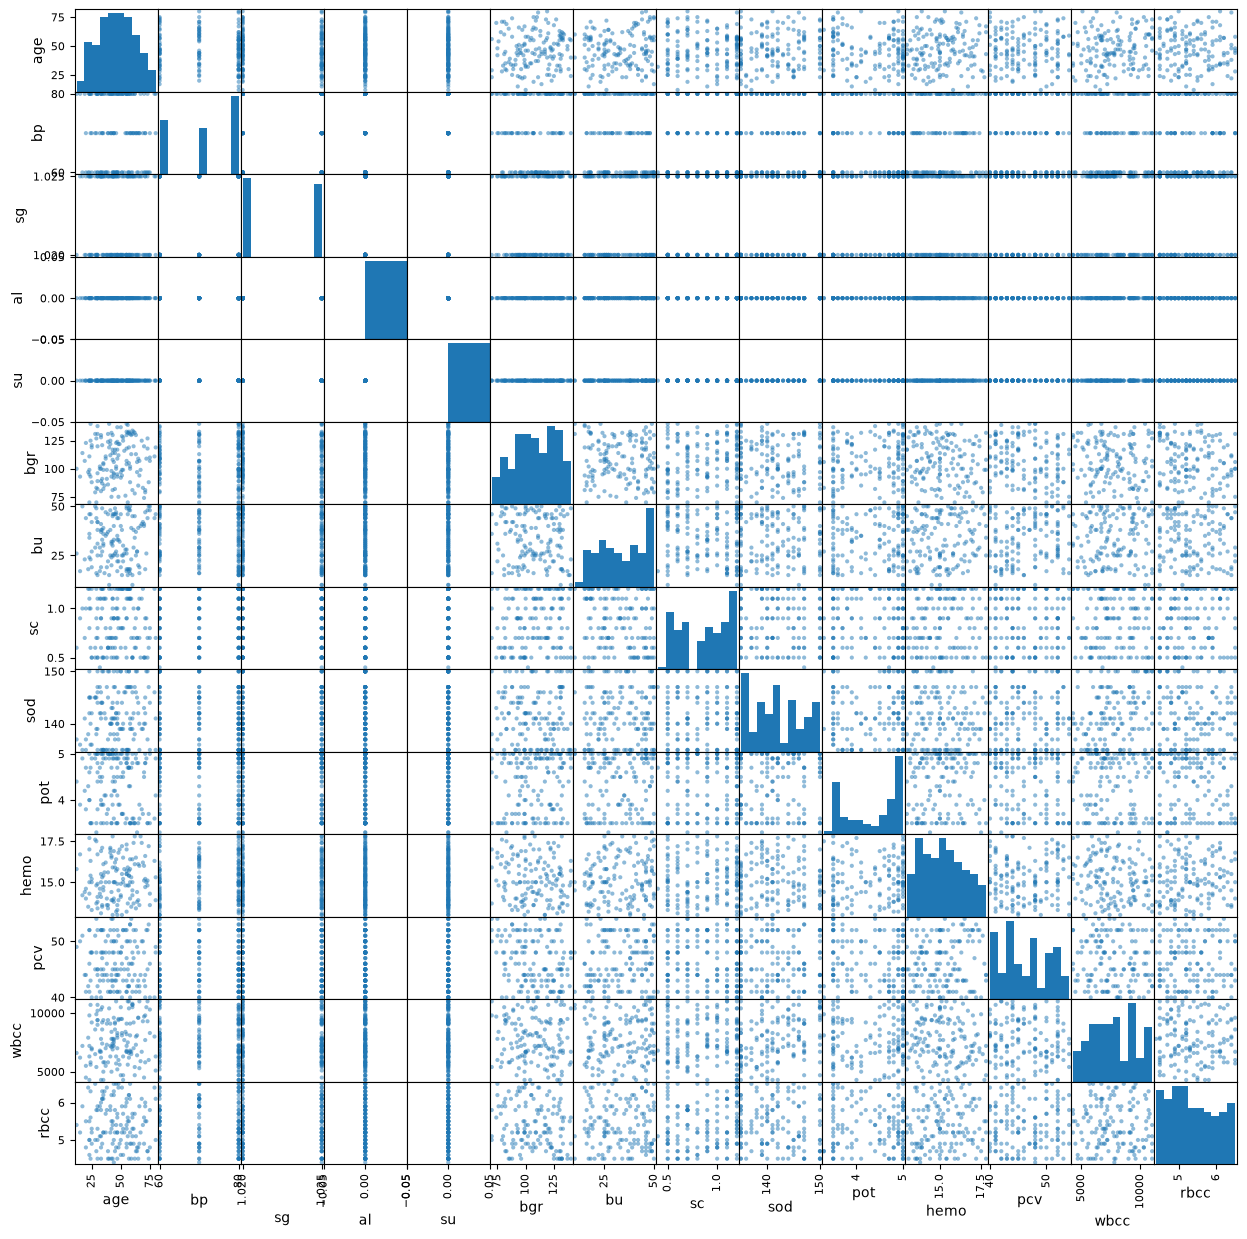

In [191]:
scatter_matrix_second_half = pd.plotting.scatter_matrix(df_second_half[numeric_cols], figsize=(15, 15), diagonal='hist', alpha=0.5)

In [192]:
df_second_half[numeric_cols].corr()

,age,bp,sg,al,su,bgr,bu,sc,sod,pot,hemo,pcv,wbcc,rbcc
age,1.000000,-0.068333,-0.085959,NaN,NaN,0.082509,0.095415,-0.008872,0.107677,-0.088791,0.066864,-0.030711,0.124333,-0.053293
bp,-0.068333,1.000000,0.069322,NaN,NaN,-0.035652,-0.075799,0.077959,-0.083054,-0.057246,0.139321,0.000740,-0.057115,-0.036952
sg,-0.085959,0.069322,1.000000,NaN,NaN,-0.050773,-0.028009,0.017278,-0.022586,0.073270,0.011313,0.009057,-0.039539,0.050100
al,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
su,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bgr,0.082509,-0.035652,-0.050773,NaN,NaN,1.000000,-0.084855,0.144595,-0.023734,0.145815,-0.133382,-0.254446,-0.095086,-0.185329
bu,0.095415,-0.075799,-0.028009,NaN,NaN,-0.084855,1.000000,-0.101177,-0.012251,0.053128,0.097056,0.127738,0.020913,-0.028607
sc,-0.008872,0.077959,0.017278,NaN,NaN,0.144595,-0.101177,1.000000,-0.088082,0.017502,0.068921,-0.027852,0.006251,0.155462
sod,0.107677,-0.083054,-0.022586,NaN,NaN,-0.023734,-0.012251,-0.088082,1.000000,0.062783,-0.021808,0.021109,0.343836,-0.063609
pot,-0.088791,-0.057246,0.073270,NaN,NaN,0.145815,0.053128,0.017502,0.062783,1.000000,0.104759,-0.149548,0.027240,-0.077404


In [193]:
corr_matrix_second_half = df_second_half[numeric_cols].corr()
upper_triangle_second_half = corr_matrix_second_half.where(np.triu(np.ones(corr_matrix_second_half.shape), k=1).astype(bool))
strong_corr_second_half = upper_triangle_second_half.stack()
strong_corr_second_half = strong_corr_second_half[(strong_corr_second_half >= 0.3) & (strong_corr_second_half <= 1)].sort_values(ascending=False)
strong_corr_second_half

sod  wbcc    0.343836
dtype: float64

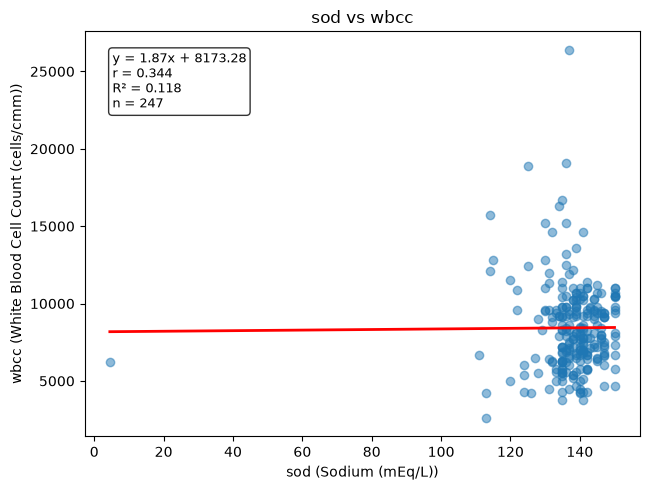

In [194]:
column_descriptions = {
    "age": "Age (years)",
    "bp": "Blood Pressure (mm/Hg)",
    "sg": "Specific Gravity",
    "al": "Albumin",
    "su": "Sugar",
    "bgr": "Blood Glucose Random (mgs/dl)",
    "bu": "Blood Urea (mgs/dl)",
    "sc": "Serum Creatinine (mgs/dl)",
    "sod": "Sodium (mEq/L)",
    "pot": "Potassium (mEq/L)",
    "hemo": "Hemoglobin (gms)",
    "pcv": "Packed Cell Volume",
    "wbcc": "White Blood Cell Count (cells/cmm)",
    "rbcc": "Red Blood Cell Count (millions/cmm)",
}

pairs = strong_corr_second_half.index.tolist()

n_cols = 3
n_rows = -(-len(pairs) // n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))
axes = axes.flatten()

for i, (col_x, col_y) in enumerate(pairs):
    pair_data = df[[col_x, col_y]].dropna()
    x = pair_data[col_x]
    y = pair_data[col_y]

    axes[i].scatter(x, y, alpha=0.5)

    slope, intercept = np.polyfit(x, y, 1)
    x_line = np.linspace(x.min(), x.max(), 100)
    axes[i].plot(x_line, slope * x_line + intercept, color="red", linewidth=2)

    r = strong_corr_second_half[(col_x, col_y)]
    stats_text = (
        f"y = {slope:.2f}x + {intercept:.2f}\n"
        f"r = {r:.3f}\n"
        f"R² = {r ** 2:.3f}\n"
        f"n = {len(pair_data)}"
    )
    axes[i].text(
        0.05, 0.95, stats_text,
        transform=axes[i].transAxes,
        verticalalignment="top",
        fontsize=9,
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.8),
    )

    axes[i].set_xlabel(f"{col_x} ({column_descriptions.get(col_x, col_x)})")
    axes[i].set_ylabel(f"{col_y} ({column_descriptions.get(col_y, col_y)})")
    axes[i].set_title(f"{col_x} vs {col_y}")

for j in range(len(pairs), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## Non-numeric data: encoding, imputer

In [195]:
non_numeric_cols = X.select_dtypes(exclude=[np.number]).columns
df_non_numeric = X[non_numeric_cols].copy()

print("DF NON-NUMERIC")
print(df_non_numeric)


DF NON-NUMERIC
          rbc        pc         pcc          ba  htn    dm  cad appet   pe  \
0         NaN    normal  notpresent  notpresent  yes   yes   no  good   no   
1         NaN    normal  notpresent  notpresent   no    no   no  good   no   
2      normal    normal  notpresent  notpresent   no   yes   no  poor   no   
3      normal  abnormal     present  notpresent  yes    no   no  poor  yes   
4      normal    normal  notpresent  notpresent   no    no   no  good   no   
5         NaN       NaN  notpresent  notpresent  yes   yes   no  good  yes   
6         NaN    normal  notpresent  notpresent   no    no   no  good   no   
7      normal  abnormal  notpresent  notpresent   no   yes   no  good  yes   
8      normal  abnormal     present  notpresent  yes   yes   no  good   no   
9    abnormal  abnormal     present  notpresent  yes   yes   no  poor   no   
10        NaN  abnormal     present  notpresent  yes   yes   no  good   no   
11   abnormal  abnormal     present  notpresent  

In [196]:
non_numeric_descriptions = {
    "rbc": "Red Blood Cells (normal, abnormal)",
    "pc": "Pus Cell (normal, abnormal)",
    "pcc": "Pus Cell Clumps (present, notpresent)",
    "ba": "Bacteria (present, notpresent)",
    "htn": "Hypertension (yes, no)",
    "dm": "Diabetes Mellitus (yes, no)",
    "cad": "Coronary Artery Disease (yes, no)",
    "appet": "Appetite (good, poor)",
    "pe": "Pedal Edema (yes, no)",
    "ane": "Anemia (yes, no)",
}
print("NON-NUMERIC COLUMN DESCRIPTIONS")
for col in df_non_numeric.columns:
    print(f"{col}: {non_numeric_descriptions.get(col, col)}")
    print(f"  unique values: {df_non_numeric[col].unique().tolist()}")

NON-NUMERIC COLUMN DESCRIPTIONS
rbc: Red Blood Cells (normal, abnormal)
  unique values: [nan, 'normal', 'abnormal']
pc: Pus Cell (normal, abnormal)
  unique values: ['normal', 'abnormal', nan]
pcc: Pus Cell Clumps (present, notpresent)
  unique values: ['notpresent', 'present', nan]
ba: Bacteria (present, notpresent)
  unique values: ['notpresent', 'present', nan]
htn: Hypertension (yes, no)
  unique values: ['yes', 'no', nan]
dm: Diabetes Mellitus (yes, no)
  unique values: ['yes', 'no', '\tno', nan]
cad: Coronary Artery Disease (yes, no)
  unique values: ['no', 'yes', nan]
appet: Appetite (good, poor)
  unique values: ['good', 'poor', nan]
pe: Pedal Edema (yes, no)
  unique values: ['no', 'yes', nan]
ane: Anemia (yes, no)
  unique values: ['no', 'yes', nan]


In [197]:
y = chronic_kidney_disease.data.targets
print(y.to_string())

      class
0       ckd
1       ckd
2       ckd
3       ckd
4       ckd
5       ckd
6       ckd
7       ckd
8       ckd
9       ckd
10      ckd
11      ckd
12      ckd
13      ckd
14      ckd
15      ckd
16      ckd
17      ckd
18      ckd
19      ckd
20      ckd
21      ckd
22      ckd
23      ckd
24      ckd
25      ckd
26      ckd
27      ckd
28      ckd
29      ckd
30      ckd
31      ckd
32      ckd
33      ckd
34      ckd
35      ckd
36      ckd
37    ckd\t
38      ckd
39      ckd
40      ckd
41      ckd
42      ckd
43      ckd
44      ckd
45      ckd
46      ckd
47      ckd
48      ckd
49      ckd
50      ckd
51      ckd
52      ckd
53      ckd
54      ckd
55      ckd
56      ckd
57      ckd
58      ckd
59      ckd
60      ckd
61      ckd
62      ckd
63      ckd
64      ckd
65      ckd
66      ckd
67      ckd
68      ckd
69      ckd
70      ckd
71      ckd
72      ckd
73      ckd
74      ckd
75      ckd
76      ckd
77      ckd
78      ckd
79      ckd
80      ckd
81      ckd
82  

In [198]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer

binary_map = {
    "abnormal": 0, "normal": 1,
    "notpresent": 0, "present": 1,
    "no": 0, "yes": 1,
    "poor": 0, "good": 1,
}

df_non_numeric_encoded = df_non_numeric.apply(lambda col: col.map(binary_map))  #This line applies the binary_map to each column in df_non_numeric, converting categorical values to numerical values (0 or 1) based on the mapping defined in binary_map. The result is a new DataFrame df_non_numeric_encoded with the same structure as df_non_numeric but with encoded numerical values.

imputer = SimpleImputer(strategy="most_frequent")
df_non_numeric_encoded = pd.DataFrame(
    imputer.fit_transform(df_non_numeric_encoded),
    columns=df_non_numeric_encoded.columns,
    index=df_non_numeric_encoded.index,
)                                                                               #This line creates a SimpleImputer object with the strategy set to "most_frequent", which means that it will fill in missing values in each column with the most frequently occurring value in that column. The imputer is then applied to df_non_numeric_encoded using the fit_transform method, which both fits the imputer to the data and transforms the data by filling in missing values. The result is converted back into a DataFrame with the same column names and index as the original df_non_numeric_encoded.

y_encoded = y["class"].str.strip().map({"ckd": 0, "notckd": 1})      #This line encodes the target variable y by mapping the string values "ckd" and "notckd" to numerical values 0 and 1, respectively. The str.strip() method is used to remove any leading or trailing whitespace from the string values before applying the mapping. The result is a new Series y_encoded containing the encoded target values.

print(df_non_numeric_encoded.to_string())
print(y_encoded.to_string())

     rbc   pc  pcc   ba  htn   dm  cad  appet   pe  ane
0    1.0  1.0  0.0  0.0  1.0  1.0  0.0    1.0  0.0  0.0
1    1.0  1.0  0.0  0.0  0.0  0.0  0.0    1.0  0.0  0.0
2    1.0  1.0  0.0  0.0  0.0  1.0  0.0    0.0  0.0  1.0
3    1.0  0.0  1.0  0.0  1.0  0.0  0.0    0.0  1.0  1.0
4    1.0  1.0  0.0  0.0  0.0  0.0  0.0    1.0  0.0  0.0
5    1.0  1.0  0.0  0.0  1.0  1.0  0.0    1.0  1.0  0.0
6    1.0  1.0  0.0  0.0  0.0  0.0  0.0    1.0  0.0  0.0
7    1.0  0.0  0.0  0.0  0.0  1.0  0.0    1.0  1.0  0.0
8    1.0  0.0  1.0  0.0  1.0  1.0  0.0    1.0  0.0  1.0
9    0.0  0.0  1.0  0.0  1.0  1.0  0.0    0.0  0.0  1.0
10   1.0  0.0  1.0  0.0  1.0  1.0  0.0    1.0  0.0  1.0
11   0.0  0.0  1.0  0.0  1.0  1.0  0.0    0.0  1.0  0.0
12   1.0  1.0  1.0  0.0  1.0  1.0  1.0    0.0  1.0  0.0
13   1.0  1.0  0.0  0.0  1.0  1.0  1.0    0.0  1.0  0.0
14   1.0  0.0  1.0  1.0  1.0  1.0  1.0    0.0  1.0  0.0
15   1.0  1.0  0.0  0.0  1.0  0.0  0.0    1.0  0.0  1.0
16   1.0  1.0  0.0  0.0  0.0  0.0  0.0    1.0  0

## Decision tree

In [199]:
from sklearn.tree import DecisionTreeClassifier
clf = DecisionTreeClassifier(criterion='gini')

In [200]:
clf = clf.fit(df_non_numeric_encoded, y_encoded) # clf is the trained Decision Tree Classifier
print(clf)

DecisionTreeClassifier()


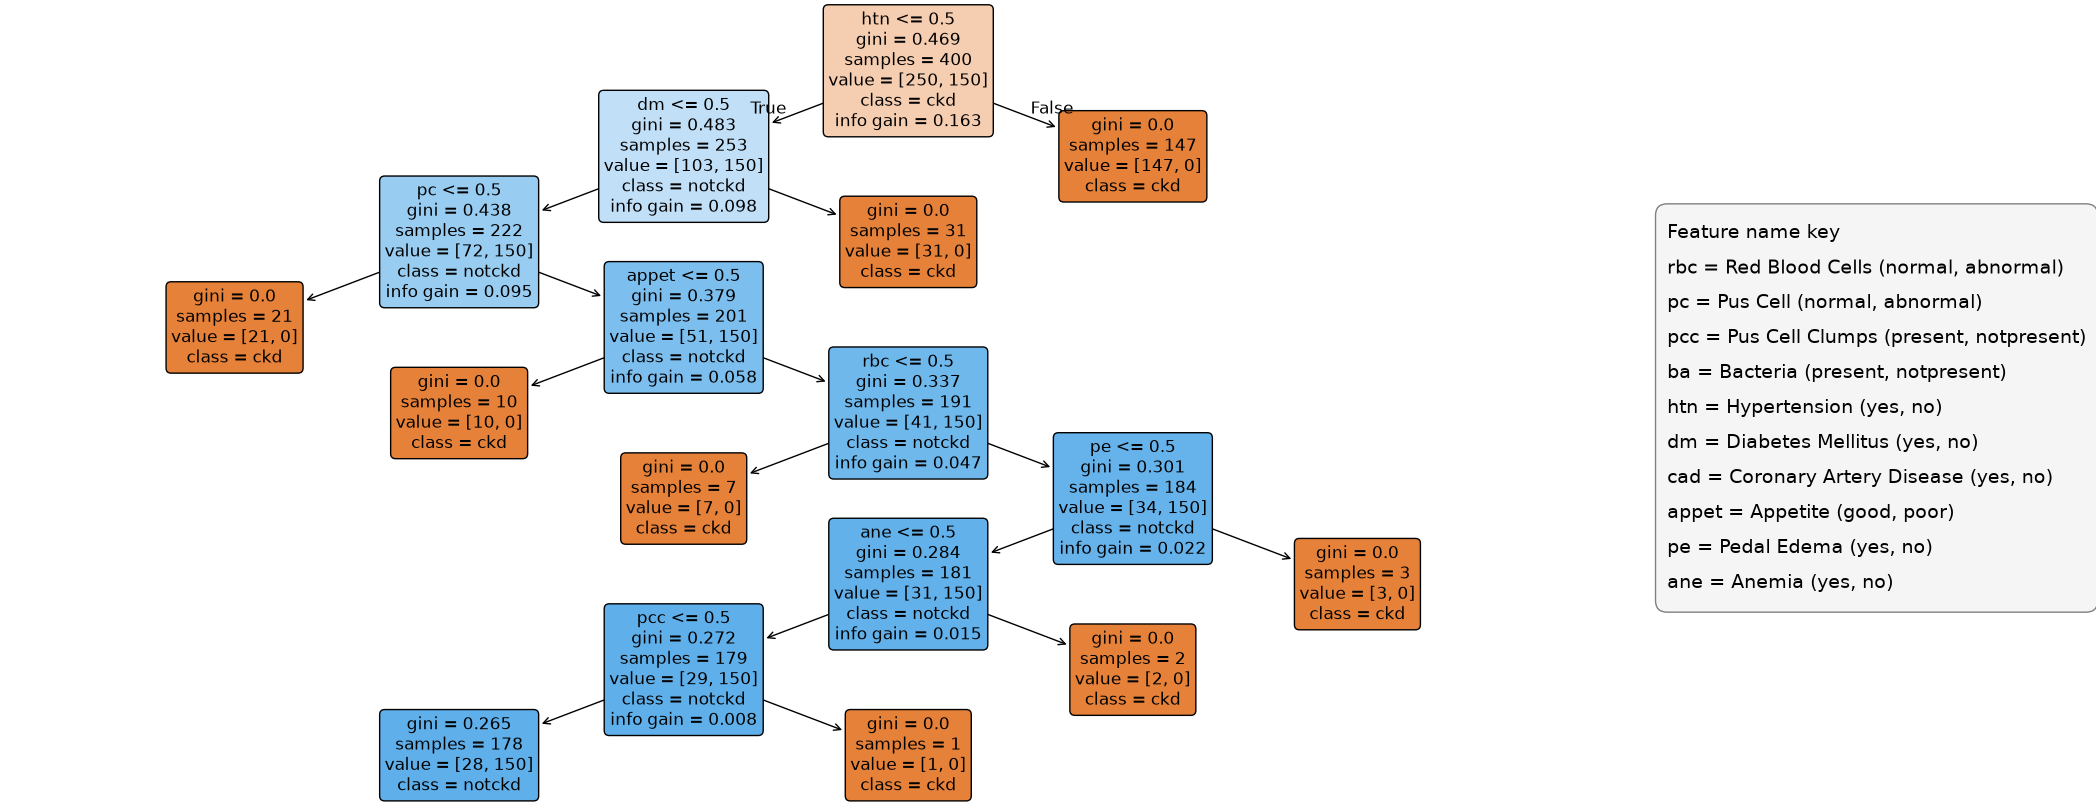

In [201]:
import re

from sklearn import tree
import matplotlib.pyplot as plt

plt.figure(figsize=(24, 10))
annotations = tree.plot_tree(
    clf,
    feature_names=df_non_numeric_encoded.columns,
    class_names=["ckd", "notckd"],
    filled=True,
    rounded=True,
    fontsize=12,
)

tree_ = clf.tree_

# Match each annotation to its tree node by parsing the "samples" and "value" numbers
# plot_tree already printed on it, rather than guessing plot_tree's internal draw order.
# Note: tree_.value stores class *proportions* (e.g. [0.5, 0.5]), not raw counts, so it
# must be multiplied by n_node_samples to get the integer counts plot_tree displays.
samples_value_to_node = {}
for node_id in range(tree_.node_count):
    samples = int(tree_.n_node_samples[node_id])
    value = tuple(int(round(v)) for v in tree_.value[node_id][0] * samples)
    samples_value_to_node[(samples, value)] = node_id

for ann in annotations:
    text = ann.get_text()
    samples_match = re.search(r"samples = (\d+)", text)
    value_match = re.search(r"value = \[([^\]]+)\]", text)
    if not samples_match or not value_match:
        continue  # not a node box (e.g. the "True"/"False" branch labels near the root)

    samples = int(samples_match.group(1))
    value = tuple(int(round(float(v))) for v in value_match.group(1).split(","))
    node_id = samples_value_to_node.get((samples, value))
    if node_id is None:
        continue

    left = tree_.children_left[node_id]
    right = tree_.children_right[node_id]
    if left == -1:
        continue  # leaf node: no split happened here, so no information gain to show

    n = tree_.weighted_n_node_samples[node_id]
    # information gain = impurity here - weighted average impurity of the two children
    gain = (
        tree_.impurity[node_id]
        - (tree_.weighted_n_node_samples[left] / n) * tree_.impurity[left]
        - (tree_.weighted_n_node_samples[right] / n) * tree_.impurity[right]
    )
    ann.set_text(text + f"\ninfo gain = {gain:.3f}")

# Legend box relating each abbreviated feature name (as used in the tree's split labels)
# to its full description, reusing the dict defined earlier for the non-numeric columns.
legend_text = "Feature name key\n" + "\n".join(
    f"{col} = {non_numeric_descriptions.get(col, col)}"
    for col in df_non_numeric_encoded.columns
)
plt.gcf().text(
    0.99, 0.5, legend_text,
    transform=plt.gcf().transFigure,
    fontsize=14,
    va="center",
    ha="right",
    multialignment="left",
    linespacing=1.8,
    bbox=dict(boxstyle="round,pad=0.6", facecolor="whitesmoke", edgecolor="gray"),
)
plt.subplots_adjust(right=0.78)

plt.show()

# Information gain measures how much a split reduces uncertainty/impurity about the class label. Concretely, for a node split into a left and right child:
#info gain = impurity(parent) − [ (n_left/n_parent) × impurity(left) + (n_right/n_parent) × impurity(right) ]
# It's "parent impurity minus the weighted-average impurity of the children." If a split perfectly separates the two classes (each child becomes pure, impurity 0), the gain equals the parent's full impurity — the maximum possible. If a split does nothing useful (children are just as mixed as the parent), the gain is close to 0.

# In your tree, impurity is measured by Gini (criterion='gini'), so this is technically "Gini gain" rather than the entropy-based information gain from information theory, but they play the same role: at every node, DecisionTreeClassifier tries every possible feature/threshold split and picks whichever one maximizes this gain value. That's why the numbers you're now seeing on each box are largest near the root (the first split does the most work separating ckd from notckd) and shrink further down the tree, where there's less impurity left to remove.


### How to read each node

Each box in the tree shows, top to bottom:

- **`NAME <= 0.5`** — the split rule tested at this node. Since our features are all 0/1-encoded, `<= 0.5` is just "is this feature 0?" (goes left/True) vs "is it 1?" (goes right/False). This line is absent on leaf nodes, since there's nothing left to split on.
- **`gini`** — the Gini impurity of the samples at this node, ranging 0 (all samples belong to one class — perfectly pure) to 0.5 (50/50 split between the two classes for a binary problem). The tree picks whichever split reduces this the most at each step.
- **`samples`** — how many training rows (out of 400) reached this node.
- **`value`** — the class breakdown of those samples, as `[count_class_0, count_class_1]` i.e. `[ckd, notckd]`.
- **`class`** — the majority class at this node, i.e. what the tree would predict if a sample stopped here. This is what the node's color represents (`filled=True`): darker shading means a purer/more confident majority.
- **`info gain`** — added on top of the default `plot_tree` output for every non-leaf node: how much the split at this node reduced Gini impurity, i.e. `impurity_here - weighted_average(impurity_left_child, impurity_right_child)`. Higher values mean that split did more work separating the two classes; this is exactly the criterion the tree greedily maximizes at each step, so it should be largest near the root and shrink further down.

## Non-numeric data: neural network.

In [202]:
df_non_numeric_encoded.shape, y_encoded.shape

#y.info(),X.info()

((400, 10), (400,))

In [203]:
from keras.models import Model
from keras.layers import Input,Dense
model = tf.keras.Sequential()
inputs = Input(shape=(10, )) #input layer with 10 features: rbc, pc, pcc, ba, htn, dm, cad, appet, pe, ane
model.add(inputs)
model.add(Dense(8, activation='relu'))# Output layer with 2 neurons for binary classification (ckd, notckd)
model.add(Dense(2, activation='softmax')) # Output layer with 2 neurons for binary classification (ckd, notckd)

In [204]:
model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 8)              │            88 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 2)              │            18 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 106 (424.00 B)

 Trainable params: 106 (424.00 B)

 Non-trainable params: 0 (0.00 B)

In [205]:
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [206]:
initial_weights = model.get_weights()

In [208]:

from keras.utils import to_categorical #

num_categories = 2
# One-hot encoding of the target y: converts class labels (0,1) into vectors, e.g. 0 -> [1,0]
y_categorical = to_categorical(y_encoded, num_categories)
# mit argmax() kann man die umgekehrte Transformation durchführen
#np.argmax([0., 1.]) # np.int64(1)
# to_categorical(1, num_categories)
print(y_encoded[0])
print(y_encoded[250])
print(y_categorical[0])
print(y_categorical[250])


0
1
[1. 0.]
[0. 1.]


In [209]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df_non_numeric_encoded, y_categorical, test_size=0.20, random_state=42, stratify=y_categorical)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.30, random_state=42, stratify=y_train)


In [210]:
X_train.shape, X_val.shape, X_test.shape, y_train.shape, y_val.shape, y_test.shape

((224, 10), (96, 10), (80, 10), (224, 2), (96, 2), (80, 2))

In [211]:
train_labels = y_train.argmax(axis=1) #argmax() returns the indices of the maximum values along an axis. In this case, it returns the class labels (0 or 1) for the training subset.
val_labels = y_val.argmax(axis=1)

print(f"Training subset used for fitting (n={len(train_labels)}):")
print(pd.Series(train_labels).value_counts().sort_index()) # this line counts the occurrences of each class label in the training subset and sorts them by index (class label).

print(f"\nValidation subset (n={len(val_labels)}):")
print(pd.Series(val_labels).value_counts().sort_index())

Training subset used for fitting (n=224):
0    140
1     84
Name: count, dtype: int64

Validation subset (n=96):
0    60
1    36
Name: count, dtype: int64


In [212]:
model.set_weights(initial_weights)

In [213]:
from keras.callbacks import Callback, EarlyStopping

accuracy_list = []
loss_list = []
val_accuracy_list = []
val_loss_list = []

class MetricsHistory(Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        accuracy_list.append(logs.get('accuracy'))
        loss_list.append(logs.get('loss'))
        val_accuracy_list.append(logs.get('val_accuracy'))
        val_loss_list.append(logs.get('val_loss'))

metrics_history = MetricsHistory()

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True,
)

In [214]:
#41
#%time model.fit(X_train, y_train, epochs=100, validation_split=0.3) # accuracy: 0.18840579688549042
#%time model.fit(X_train, y_train, epochs=500, validation_split=0.3) # accuracy: 0.782608687877655
#%time model.fit(X_train, y_train, epochs=1000, validation_split=0.3) # accuracy: 0.8840579986572266
%time model.fit(X_train, y_train, epochs=1000, validation_data=(X_val, y_val), callbacks=[metrics_history, early_stopping])
#early stopping will stop training if the validation loss does not improve for 20 consecutive epochs, and it will restore the best weights from the epoch with the lowest validation loss.

Epoch 1/1000
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.5089 - loss: 0.6172 - val_accuracy: 0.5729 - val_loss: 0.5687
Epoch 2/1000
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5134 - loss: 0.5973 - val_accuracy: 0.5729 - val_loss: 0.5486
Epoch 3/1000
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5179 - loss: 0.5793 - val_accuracy: 0.8854 - val_loss: 0.5303
Epoch 4/1000
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8036 - loss: 0.5630 - val_accuracy: 0.8854 - val_loss: 0.5132
Epoch 5/1000
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8080 - loss: 0.5476 - val_accuracy: 0.8854 - val_loss: 0.4972
Epoch 6/1000
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8125 - loss: 0.5331 - val_accuracy: 0.8854 - val_loss: 0.4819
Epoch 7/1000
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8125 - loss: 0.5191 - val_accuracy: 0.8854 - val_loss: 0.4687
Epoch 8/1000
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8125 - loss: 0.5063 - val_accuracy: 0.8854 - val_loss

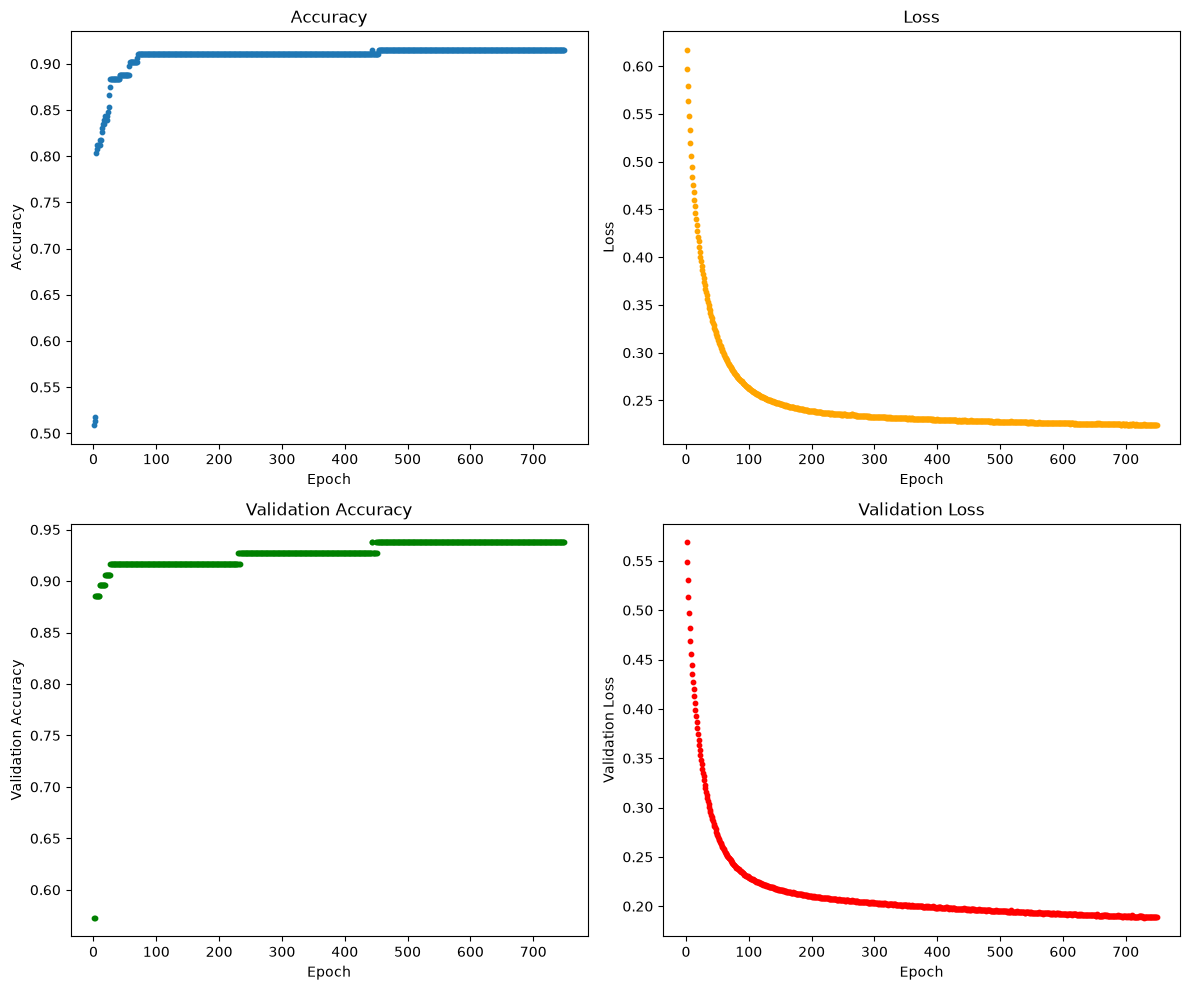

In [216]:
epochs_range = range(1, len(accuracy_list) + 1)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].scatter(epochs_range, accuracy_list, s=10)
axes[0, 0].set_title("Accuracy")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Accuracy")

axes[0, 1].scatter(epochs_range, loss_list, s=10, color="orange")
axes[0, 1].set_title("Loss")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Loss")

axes[1, 0].scatter(epochs_range, val_accuracy_list, s=10, color="green")
axes[1, 0].set_title("Validation Accuracy")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Validation Accuracy")

axes[1, 1].scatter(epochs_range, val_loss_list, s=10, color="red")
axes[1, 1].set_title("Validation Loss")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Validation Loss")

plt.tight_layout()
plt.show()

In [217]:
train_loss, train_accuracy = model.evaluate(X_train, y_train) # Anders als in sklearn
train_loss, train_accuracy

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9152 - loss: 0.2245 


(0.2244677096605301, 0.9151785969734192)

In [218]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)
test_loss, test_accuracy

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9625 - loss: 0.1433  


(0.14325293898582458, 0.9624999761581421)

In [219]:
#42
#X_train.shape
print(X_test.iloc[3].values, y_test[3])
print(X_test.iloc[23].values, y_test[23])
print(X_test.iloc[3].values, y_test[46])
print(X_test.iloc[23].values, y_test[77])

# For training sample #3: → label [0., 1.], i.e. class 0 (ckd)
# For training sample #23: → label [1., 0.], i.e. class 1 (notckd)
# For training sample #46: → label [0., 1.], i.e. class 0 (ckd)
#For training sample #77: → label [1., 0.], i.e. class 1 (notckd)

[1. 1. 0. 0. 0. 0. 0. 1. 0. 0.] [0. 1.]
[1. 1. 0. 0. 0. 0. 0. 1. 1. 0.] [1. 0.]
[1. 1. 0. 0. 0. 0. 0. 1. 0. 0.] [0. 1.]
[1. 1. 0. 0. 0. 0. 0. 1. 1. 0.] [1. 0.]


In [220]:
#prüfen:
print(model.predict(np.array([X_test.iloc[3] ])))
print(model.predict(np.array([X_test.iloc[23] ])))
print(model.predict(np.array([X_test.iloc[49] ])))
print(model.predict(np.array([X_test.iloc[77] ])))
# epochs 2000: array([[9.9937588e-01, 6.2416983e-04, 3.7879366e-10]], dtype=float32)
# model predicts class 0 (ckd) with high confidence

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
[[0.18247192 0.81752807]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
[[0.9983767  0.00162325]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
[[0.18247192 0.81752807]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
[[1.0000000e+00 1.0601175e-12]]


In [221]:
predictions = model.predict(X_test.values)

comparison = pd.DataFrame({
    "actual_class": y_test.argmax(axis=1), # This is the actual class label (0 for ckd, 1 for not ckd). Argmax is used to convert the one-hot encoded vector back to the original class label.
    "predicted_class": predictions.argmax(axis=1), # This is the predicted class label (0 for ckd, 1 for not ckd)
    "predicted_prob_ckd": predictions[:, 0], # This is the predicted probability for class 0 (ckd)
    "predicted_prob_notckd": predictions[:, 1], # This is the predicted probability for class 1 (not ckd)
})
comparison["correct"] = comparison["actual_class"] == comparison["predicted_class"]

print(f"Overall accuracy: {comparison['correct'].mean():.4f}")
print(f"Misclassified: {(~comparison['correct']).sum()} / {len(comparison)}")

print(comparison.to_string(index=False))

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
Overall accuracy: 0.9625
Misclassified: 3 / 80
 actual_class  predicted_class  predicted_prob_ckd  predicted_prob_notckd  correct
            1                1            0.182472           8.175281e-01     True
            0                0            1.000000           7.359178e-16     True
            0                0            0.999893           1.067141e-04     True
            1                1            0.182472           8.175281e-01     True
            0                0            1.000000           4.487265e-08     True
            0                0            0.999995           4.749292e-06     True
            1                1            0.182472           8.175281e-01     True
            0                0            1.000000           1.477677e-10     True
            0                1            0.182472           8.175281e-01    False
            0                0            0.999974           2.612072e-05     True
  

## Selected numeric data: select, encode, impute, outliers

In [222]:
numeric_cols_selected = ['sc', 'bu', 'hemo', 'pcv', 'sg', 'rbcc']
df_numeric = X[numeric_cols_selected].copy()
df_numeric

,sc,bu,hemo,pcv,sg,rbcc
0,1.20,36.0,15.4,44.0,1.020,5.2
1,0.80,18.0,11.3,38.0,1.020,NaN
2,1.80,53.0,9.6,31.0,1.010,NaN
3,3.80,56.0,11.2,32.0,1.005,3.9
4,1.40,26.0,11.6,35.0,1.010,4.6
5,1.10,25.0,12.2,39.0,1.015,4.4
6,24.00,54.0,12.4,36.0,1.010,NaN
7,1.10,31.0,12.4,44.0,1.015,5.0
8,1.90,60.0,10.8,33.0,1.015,4.0
9,7.20,107.0,9.5,29.0,1.020,3.7


In [223]:
from sklearn.preprocessing import MinMaxScaler

numeric_imputer = SimpleImputer(strategy="mean")
df_numeric_imputed = pd.DataFrame(
    numeric_imputer.fit_transform(df_numeric),
    columns=df_numeric.columns,
    index=df_numeric.index,
)

scaler = MinMaxScaler()
df_numeric_scaled = pd.DataFrame(
    scaler.fit_transform(df_numeric_imputed),
    columns=df_numeric_imputed.columns,
    index=df_numeric_imputed.index,
)

print(df_numeric_scaled.to_string())

           sc        bu      hemo       pcv        sg      rbcc
0    0.010582  0.088575  0.836735  0.777778  0.750000  0.525424
1    0.005291  0.042362  0.557823  0.644444  0.750000  0.441938
2    0.018519  0.132221  0.442177  0.488889  0.250000  0.441938
3    0.044974  0.139923  0.551020  0.511111  0.000000  0.305085
4    0.013228  0.062901  0.578231  0.577778  0.250000  0.423729
5    0.009259  0.060334  0.619048  0.666667  0.500000  0.389831
6    0.312169  0.134788  0.632653  0.600000  0.250000  0.441938
7    0.009259  0.075738  0.632653  0.777778  0.500000  0.491525
8    0.019841  0.150193  0.523810  0.533333  0.500000  0.322034
9    0.089947  0.270860  0.435374  0.444444  0.750000  0.271186
10   0.047619  0.137356  0.428571  0.422222  0.250000  0.441938
11   0.030423  0.150193  0.523810  0.511111  0.250000  0.288136
12   0.022487  0.181001  0.448980  0.422222  0.500000  0.220339
13   0.055556  0.216945  0.455782  0.664100  0.620397  0.441938
14   0.048942  0.227214  0.170068  0.155

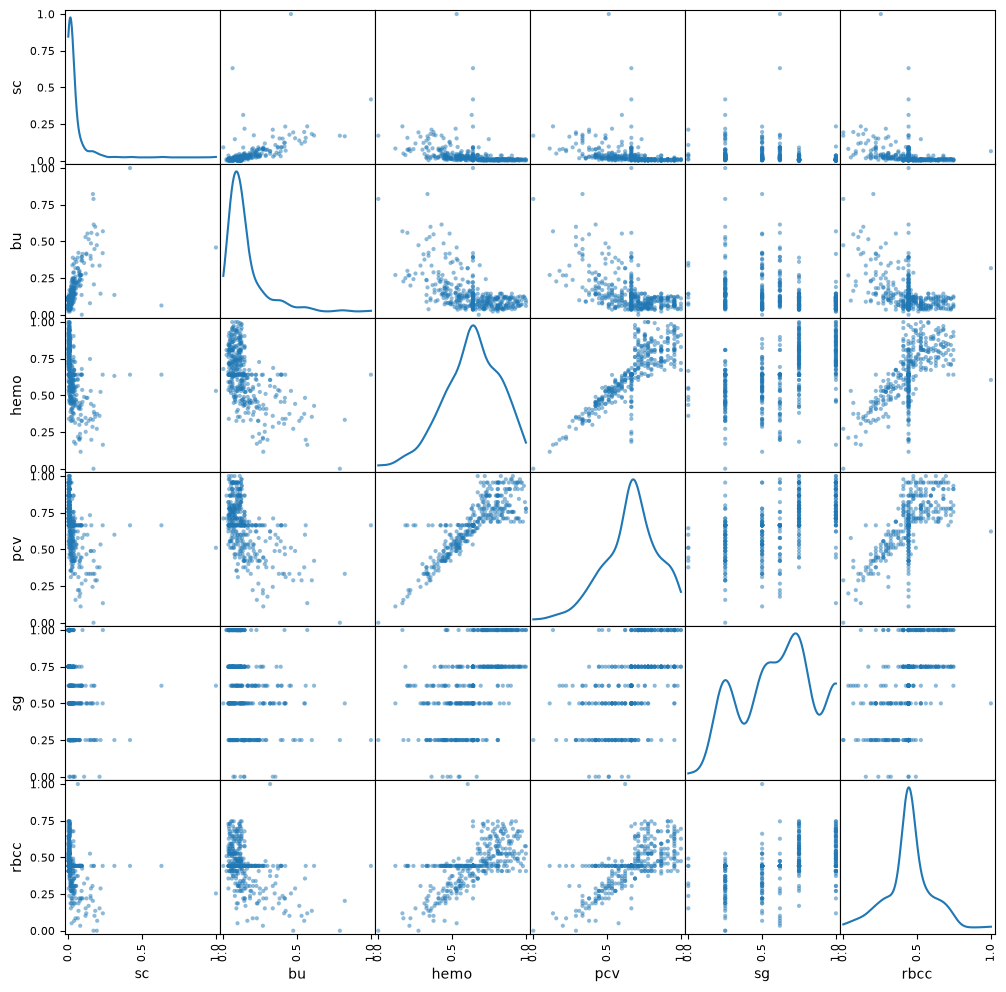

In [224]:
scatter_matrix = pd.plotting.scatter_matrix(df_numeric_scaled, figsize=(12, 12), diagonal='kde')

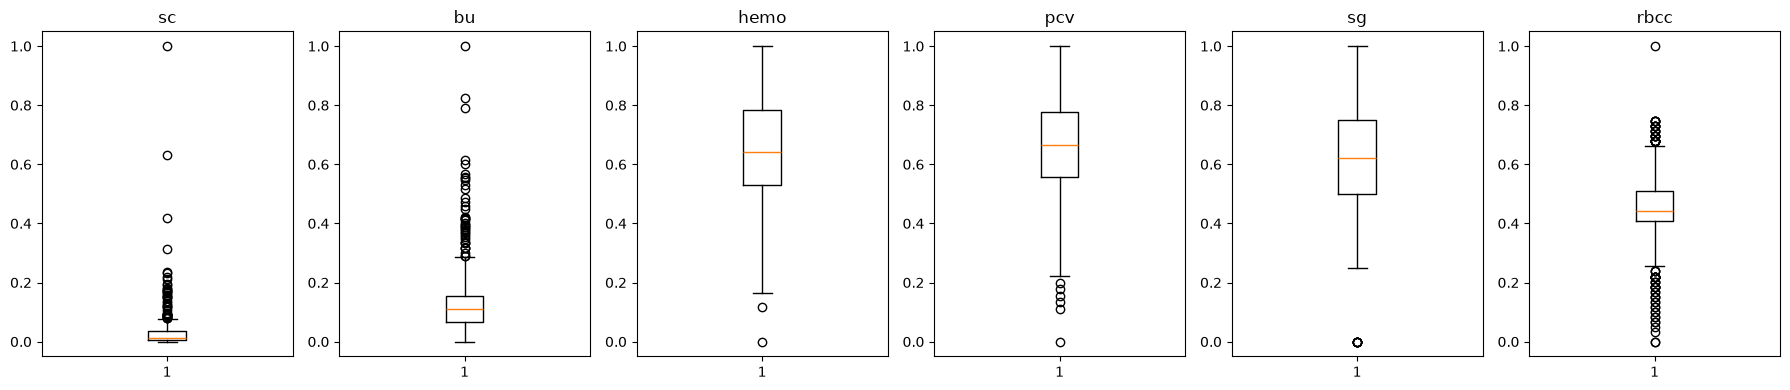

,count,pct,lower_bound,upper_bound
rbcc,67.0,16.75,0.254,0.661
sc,44.0,11.00,-0.036,0.078
bu,41.0,10.25,-0.068,0.289
sg,7.0,1.75,0.125,1.125
pcv,6.0,1.50,0.222,1.111
hemo,2.0,0.50,0.146,1.167


In [225]:
# boxplot per numeric column to visually spot outliers (values scaled to 0-1 by MinMaxScaler)
fig, axes = plt.subplots(1, len(df_numeric_scaled.columns), figsize=(3 * len(df_numeric_scaled.columns), 4))
for ax, col in zip(axes, df_numeric_scaled.columns):
    ax.boxplot(df_numeric_scaled[col])
    ax.set_title(col)
plt.tight_layout()
plt.show()

# IQR method: flag values outside [Q1 - 1.5*IQR, Q3 + 1.5*IQR] as outliers
outlier_summary = {}
for col in df_numeric_scaled.columns:
    q1 = df_numeric_scaled[col].quantile(0.25)
    q3 = df_numeric_scaled[col].quantile(0.75)
    iqr = q3 - q1 # interquartile range is the difference between the 75th and 25th percentiles
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (df_numeric_scaled[col] < lower) | (df_numeric_scaled[col] > upper)  # True where value is an outlier
    outlier_summary[col] = {
        "count": int(mask.sum()),  # number of outlier rows for this column
        "pct": round(100 * mask.sum() / len(df_numeric_scaled), 2),  # outliers as % of all 400 rows
        "lower_bound": round(lower, 3),  # anything below this is a low outlier
        "upper_bound": round(upper, 3),  # anything above this is a high outlier
    }

# summary table, one row per column, worst offenders (most outliers) first
outlier_df = pd.DataFrame(outlier_summary).T.sort_values("count", ascending=False)
outlier_df

# SC: Many outliers on the high end, including some very extreme values around 0.6–1.0.
# BU: A large number of upper outliers, extending up to 1.0.
# Hemo: Relatively few outliers; a couple of low values.
# PCV: Several low-end outliers, including values near 0.
# SG: Very few obvious outliers, mainly around 0.
# RBCC: Many outliers, especially on the low side, plus one high outlier around 1.0.

# How to read the plot

# The box represents the middle 50% of the data (IQR).
# The whiskers show the typical range.
# The individual circles (○) are observations classified as outliers, usually according to:
# Lower whisker = x < Q1 - 1.5(IQR)
# or
# Upper whisker = x > Q3 + 1.5(IQR)
# So, visually, SC, BU, and RBCC have the most prominent outlier problems in this plot.
# If you're doing data preprocessing, though, don't automatically delete these outliers—in a medical dataset, extreme values can be genuine observations.



## Combine non-numeric (encoded) + numeric (scaled) features

In [226]:
df_combined = pd.concat([df_non_numeric_encoded, df_numeric_scaled], axis=1)
print(df_combined.shape)
df_combined

(400, 16)


,rbc,pc,pcc,ba,htn,dm,cad,appet,pe,ane,sc,bu,hemo,pcv,sg,rbcc
0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.010582,0.088575,0.836735,0.777778,0.750000,0.525424
1,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.005291,0.042362,0.557823,0.644444,0.750000,0.441938
2,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.018519,0.132221,0.442177,0.488889,0.250000,0.441938
3,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.044974,0.139923,0.551020,0.511111,0.000000,0.305085
4,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.013228,0.062901,0.578231,0.577778,0.250000,0.423729
5,1.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0,0.009259,0.060334,0.619048,0.666667,0.500000,0.389831
6,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.312169,0.134788,0.632653,0.600000,0.250000,0.441938
7,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.009259,0.075738,0.632653,0.777778,0.500000,0.491525
8,1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.019841,0.150193,0.523810,0.533333,0.500000,0.322034
9,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.089947,0.270860,0.435374,0.444444,0.750000,0.271186


## Combined data: Neural network

In [227]:
# from keras.utils import to_categorical

# num_categories = 2
# # One-hot encoding of the target y: converts class labels (0,1) into vectors, e.g. 0 -> [1,0]
# y_categorical = to_categorical(y_encoded, num_categories)

# print(y_encoded[0], y_categorical[0])
# print(y_encoded[250], y_categorical[250])

In [228]:
from keras.layers import Input, Dense

model = tf.keras.Sequential()
inputs = Input(shape=(df_combined.shape[1],))  # 10 non-numeric + 6 numeric = 16 features
model.add(inputs)
model.add(Dense(8, activation='relu'))
model.add(Dense(2, activation='softmax'))  # Output layer with 2 neurons for binary classification (ckd, notckd)

In [229]:
model.compile(optimizer='adam',
              #loss=keras.losses.CategoricalFocalCrossentropy(),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [230]:
initial_weights = model.get_weights()

In [231]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(df_combined, y_categorical, test_size=0.20, random_state=42, stratify=y_categorical)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.30, random_state=42, stratify=y_train)

In [232]:
X_train.shape, X_val.shape, X_test.shape, y_train.shape, y_val.shape, y_test.shape

((224, 16), (96, 16), (80, 16), (224, 2), (96, 2), (80, 2))

In [233]:
train_labels = y_train.argmax(axis=1)
val_labels = y_val.argmax(axis=1)

print(f"Training subset used for fitting (n={len(train_labels)}):")
print(pd.Series(train_labels).value_counts().sort_index()) # sort_index() is used to sort the counts by class label (0, 1) for better readability.

print(f"\nValidation subset (n={len(val_labels)}):")
print(pd.Series(val_labels).value_counts().sort_index())

Training subset used for fitting (n=224):
0    140
1     84
Name: count, dtype: int64

Validation subset (n=96):
0    60
1    36
Name: count, dtype: int64


In [234]:
model.set_weights(initial_weights)

In [235]:
from keras.callbacks import Callback, EarlyStopping

accuracy_list = []
loss_list = []
val_accuracy_list = []
val_loss_list = []

class MetricsHistory(Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        accuracy_list.append(logs.get('accuracy'))
        loss_list.append(logs.get('loss'))
        val_accuracy_list.append(logs.get('val_accuracy'))
        val_loss_list.append(logs.get('val_loss'))

metrics_history = MetricsHistory()

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True,
)

In [236]:
%time model.fit(X_train, y_train, epochs=1000, validation_data=(X_val, y_val), callbacks=[metrics_history, early_stopping])

Epoch 1/1000
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.4777 - loss: 0.8061 - val_accuracy: 0.5000 - val_loss: 0.8104
Epoch 2/1000
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4911 - loss: 0.7740 - val_accuracy: 0.5208 - val_loss: 0.7733
Epoch 3/1000
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4152 - loss: 0.7423 - val_accuracy: 0.4375 - val_loss: 0.7383
Epoch 4/1000
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3795 - loss: 0.7108 - val_accuracy: 0.3750 - val_loss: 0.7038
Epoch 5/1000
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3973 - loss: 0.6820 - val_accuracy: 0.4375 - val_loss: 0.6703
Epoch 6/1000
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4777 - loss: 0.6525 - val_accuracy: 0.5000 - val_loss: 0.6376
Epoch 7/1000
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5536 - loss: 0.6196 - val_accuracy: 0.5729 - val_loss: 0.6065
Epoch 8/1000
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5938 - loss: 0.5905 - val_accuracy: 0.6042 - val_loss

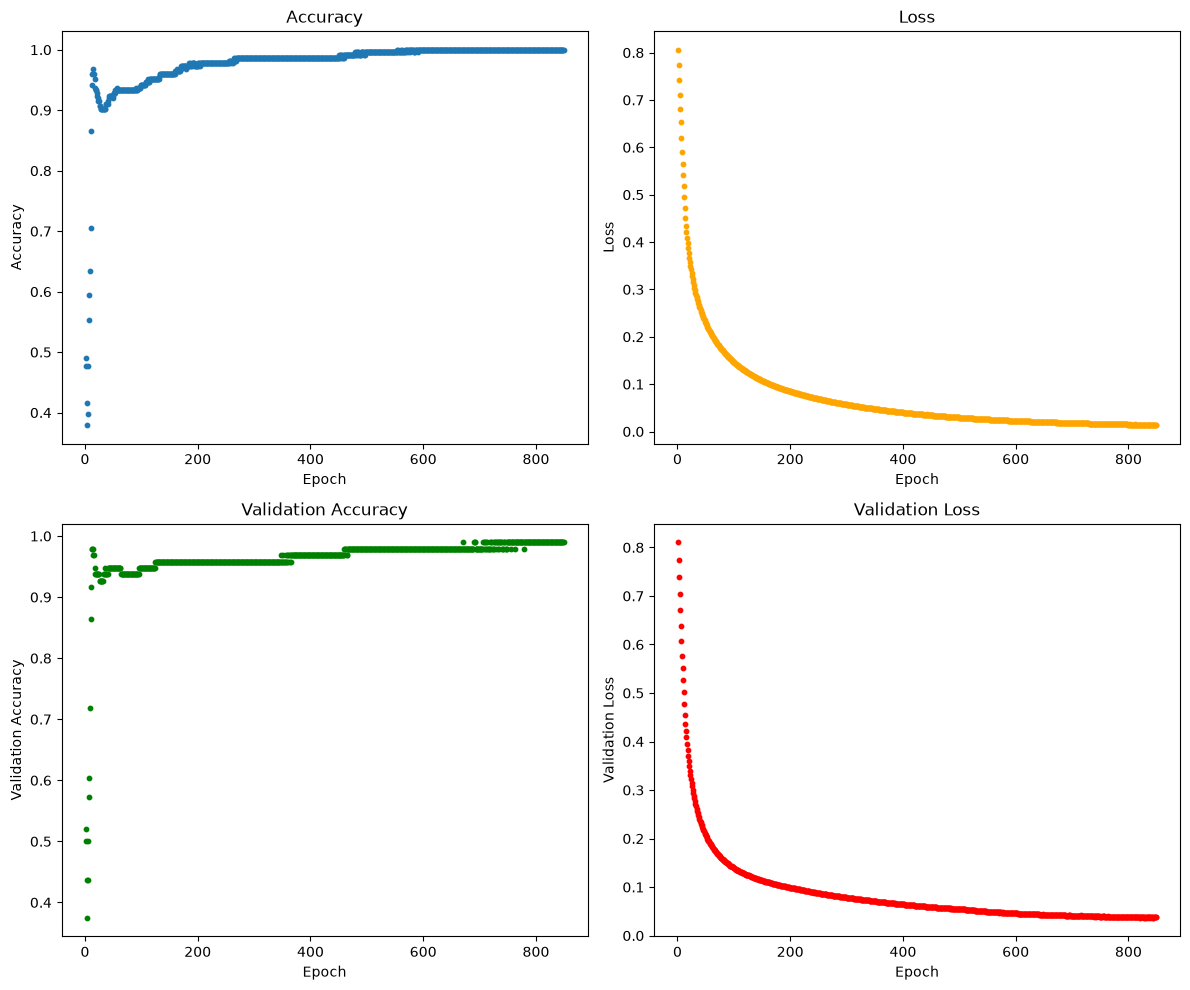

In [237]:
epochs_range = range(1, len(accuracy_list) + 1)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].scatter(epochs_range, accuracy_list, s=10)
axes[0, 0].set_title("Accuracy")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Accuracy")

axes[0, 1].scatter(epochs_range, loss_list, s=10, color="orange")
axes[0, 1].set_title("Loss")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Loss")

axes[1, 0].scatter(epochs_range, val_accuracy_list, s=10, color="green")
axes[1, 0].set_title("Validation Accuracy")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Validation Accuracy")

axes[1, 1].scatter(epochs_range, val_loss_list, s=10, color="red")
axes[1, 1].set_title("Validation Loss")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Validation Loss")

plt.tight_layout()
plt.show()

In [238]:
train_loss, train_accuracy = model.evaluate(X_train, y_train)
train_loss, train_accuracy

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 0.0141 


(0.014056594111025333, 1.0)

In [239]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)
test_loss, test_accuracy

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9875 - loss: 0.0627 


(0.06271255016326904, 0.987500011920929)

In [240]:
print(X_test.iloc[3].values, y_test[3]) # This is a test sample with class label 0 (ckd)
print("**********")
print(X_test.iloc[23].values, y_test[23]) # This is a test sample with class label 1 (not ckd)
print("**********")
print(X_test.iloc[49].values, y_test[49]) # This is a test sample with class label 1 (not ckd)
print("**********")
print(X_test.iloc[77].values, y_test[77]) # This is a test sample with class label 0 (ckd)

[1.         1.         0.         0.         0.         0.
 0.         1.         0.         0.         0.00132275 0.03465982
 0.80952381 0.82222222 1.         0.54237288] [0. 1.]
**********
[1.         1.         0.         0.         0.         0.
 0.         1.         1.         0.         0.00793651 0.11424904
 0.6412542  0.66409997 0.75       0.44193813] [1. 0.]
**********
[1.         1.         0.         0.         0.         0.
 0.         1.         0.         0.         0.00925926 0.0885751
 0.7755102  0.95555556 1.         0.6779661 ] [0. 1.]
**********
[0.         0.         0.         0.         1.         1.
 0.         0.         1.         0.         0.07804233 0.19383825
 0.44897959 0.42222222 0.25       0.44193813] [1. 0.]


In [241]:
print(model.predict(np.array([X_test.iloc[3]])))
print(model.predict(np.array([X_test.iloc[23]])))
print(model.predict(np.array([X_test.iloc[49]])))
print(model.predict(np.array([X_test.iloc[77]])))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
[[4.1896253e-04 9.9958104e-01]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
[[9.9998403e-01 1.5982296e-05]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
[[2.3219352e-04 9.9976784e-01]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
[[1.000000e+00 8.791034e-16]]


In [242]:
predictions = model.predict(X_test.values)

comparison = pd.DataFrame({
    "actual_class": y_test.argmax(axis=1), # This is the actual class label (0 for ckd, 1 for not ckd). Argmax is used to convert the one-hot encoded vector back to the original class label.
    "predicted_class": predictions.argmax(axis=1), # This is the predicted class label (0 for ckd, 1 for not ckd)
    "predicted_prob_ckd": predictions[:, 0], # This is the predicted probability for class 0 (ckd)
    "predicted_prob_notckd": predictions[:, 1], # This is the predicted probability for class 1 (not ckd)
})
comparison["correct"] = comparison["actual_class"] == comparison["predicted_class"]

print(f"Overall accuracy: {comparison['correct'].mean():.4f}")
print(f"Misclassified: {(~comparison['correct']).sum()} / {len(comparison)}")

print(comparison.to_string(index=False))

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
Overall accuracy: 0.9875
Misclassified: 1 / 80
 actual_class  predicted_class  predicted_prob_ckd  predicted_prob_notckd  correct
            1                1            0.001146           9.988545e-01     True
            0                0            1.000000           1.235294e-20     True
            0                0            0.999999           8.873587e-07     True
            1                1            0.000419           9.995810e-01     True
            0                0            0.999997           3.063984e-06     True
            0                0            0.999999           1.364222e-06     True
            1                1            0.000109           9.998906e-01     True
            0                0            1.000000           7.047003e-15     True
            0                0            0.999530           4.699243e-04     True
            0                0            0.998668           1.332145e-03     True
  